# Pipeline piloto — tarefa de decisão em vídeo

## Objetivo
Consolidar e testar o processamento de dois participantes,
mantendo separadas as duas runs de cada participante.

## Participantes e tarefa
- Participantes: sub-001 e sub-002.
- Sessão: ses-01.
- Tarefa: dm.
- Runs: 1 e 2.

## Âmbito
Preparação dos sinais fNIRS e fisiológicos, extração de épocas,
associação do comportamento e verificação temporal.

Não executar GLM ou comparações estatísticas entre grupos.

## Referências dos eventos
- Vídeo: trigger 120.
- Decisão: trigger 130.
- Baseline local: −1 a 0 s antes do respetivo evento.

A observação da decisão não termina na tecla de resposta.

## Parâmetros temporais da tarefa
- Limite de resposta: 6 s.
- Fixação pós-resposta: 2,5 s.

## Preservação
- Não alterar ficheiros originais.
- Não substituir os resultados dos notebooks anteriores.
- Não reutilizar automaticamente decisões específicas de uma run.
- Guardar os novos resultados numa versão própria.

## Etapa 1 — Localização dos ficheiros
Verificar a existência dos SNIRF e dos CSV comportamentais
esperados para as quatro combinações participante/run.

O SNIRF deve ter o mesmo nome da pasta onde se encontra,
acrescido da extensão .snirf.

Nesta etapa:
- Não carregar sinais.
- Não filtrar.
- Não criar épocas.
- Não criar ou substituir resultados.

A existência de um ficheiro não confirma a sua identidade,
qualidade ou correspondência temporal.

In [1]:
# ============================================================
# ETAPA 1 — CONFIGURAÇÃO DO PILOTO E INVENTÁRIO DOS FICHEIROS
# ============================================================

from pathlib import Path
import sys
import pandas as pd

# ------------------------------------------------------------
# 1.1 Pasta principal e âmbito do piloto
# ------------------------------------------------------------

BASE_DIR = Path(
    r"C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra"
    r"\PhD_Project_ARDITI_Guilherme Saldanha"
    r"\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI"
)

PARTICIPANTES_PILOTO = ["sub-001", "sub-002"]
SESSAO_PILOTO = "ses-01"
TAREFA_PILOTO = "dm"
RUNS_PILOTO = [1, 2]

VERSAO_PIPELINE_PILOTO = "pilot_dm_epochs_v01"

DURACAO_MAX_RESPOSTA_S = 6.0
DURACAO_FIXACAO_POS_RESPOSTA_S = 2.5

BASELINE_EPOCAS_S = (-1.0, 0.0)
JANELA_EPOCAS_S = (-5.0, 25.0)

AJUSTAR_GLM = False

if not BASE_DIR.is_dir():
    raise FileNotFoundError(
        f"A pasta principal não foi encontrada:\n{BASE_DIR}"
    )


# ------------------------------------------------------------
# 1.2 Inventariar ficheiros, sem os abrir ou alterar
# ------------------------------------------------------------

registos_inventario_piloto = []

for sujeito in PARTICIPANTES_PILOTO:
    pasta_sujeito = BASE_DIR / sujeito
    pasta_psychopy = pasta_sujeito / "psychopy"

    numero_sujeito = sujeito.removeprefix("sub-")

    for numero_run in RUNS_PILOTO:
        nome_pasta_run = (
            f"{sujeito}_{SESSAO_PILOTO}"
            f"_tk-{TAREFA_PILOTO}"
            f"_run-{numero_run}"
            f"_nirs_{numero_sujeito}"
        )

        pasta_run = (
            pasta_sujeito
            / "nirs"
            / nome_pasta_run
        )

        # O nome do SNIRF é obtido a partir do nome da pasta.
        caminho_snirf = (
            pasta_run
            / f"{pasta_run.name}.snirf"
        )

        snirf_encontrados = (
            sorted(
                caminho
                for caminho in pasta_run.iterdir()
                if caminho.is_file()
                and caminho.suffix.lower() == ".snirf"
            )
            if pasta_run.is_dir()
            else []
        )

        prefixo_csv = (
            f"{sujeito}_{SESSAO_PILOTO}"
            f"_tk-{TAREFA_PILOTO}"
            f"_run-{numero_run}_psychopy_"
        )

        csv_encontrados = (
            sorted(
                caminho
                for caminho in pasta_psychopy.iterdir()
                if caminho.is_file()
                and caminho.suffix.lower() == ".csv"
                and caminho.name.startswith(prefixo_csv)
            )
            if pasta_psychopy.is_dir()
            else []
        )

        problemas = []

        if not pasta_sujeito.is_dir():
            problemas.append("pasta do participante ausente")

        if not pasta_run.is_dir():
            problemas.append("pasta da run ausente")

        if not caminho_snirf.is_file():
            problemas.append("SNIRF com nome esperado ausente")

        if len(snirf_encontrados) != 1:
            problemas.append(
                f"{len(snirf_encontrados)} SNIRF na pasta"
            )

        if len(csv_encontrados) != 1:
            problemas.append(
                f"{len(csv_encontrados)} CSV comportamentais candidatos"
            )

        if (
            caminho_snirf.is_file()
            and caminho_snirf.stat().st_size == 0
        ):
            problemas.append("SNIRF vazio")

        if (
            len(csv_encontrados) == 1
            and csv_encontrados[0].stat().st_size == 0
        ):
            problemas.append("CSV comportamental vazio")

        pasta_saida_prevista = (
            pasta_sujeito
            / "fNIRS_epochs_derivatives"
            / VERSAO_PIPELINE_PILOTO
            / pasta_run.name
        )

        registos_inventario_piloto.append({
            "sujeito": sujeito,
            "sessao": SESSAO_PILOTO,
            "tarefa": TAREFA_PILOTO,
            "run": numero_run,
            "id_gravacao": pasta_run.name,
            "snirf_esperado_existe": caminho_snirf.is_file(),
            "n_snirf_na_pasta": len(snirf_encontrados),
            "n_csv_candidatos": len(csv_encontrados),
            "caminho_snirf": str(caminho_snirf),
            "csv_candidato": (
                str(csv_encontrados[0])
                if len(csv_encontrados) == 1
                else None
            ),
            "snirf_encontrados": " | ".join(
                caminho.name for caminho in snirf_encontrados
            ),
            "csv_encontrados": " | ".join(
                caminho.name for caminho in csv_encontrados
            ),
            "pasta_saida_prevista": str(pasta_saida_prevista),
            "estado": (
                "LOCALIZADO"
                if not problemas
                else "REVER"
            ),
            "observacoes": "; ".join(problemas),
        })

df_inventario_piloto = pd.DataFrame(
    registos_inventario_piloto
)


# ------------------------------------------------------------
# 1.3 Apresentar o resultado
# ------------------------------------------------------------

print("=" * 70)
print("PILOTO DM — LOCALIZAÇÃO DOS FICHEIROS")
print("=" * 70)

print(f"Python: {sys.executable}")
print(f"Versão prevista: {VERSAO_PIPELINE_PILOTO}")

print(
    df_inventario_piloto[
        [
            "sujeito",
            "run",
            "snirf_esperado_existe",
            "n_snirf_na_pasta",
            "n_csv_candidatos",
            "estado",
            "observacoes",
        ]
    ].to_string(index=False)
)

for _, linha in df_inventario_piloto.iterrows():
    print(
        f"\n--- {linha['sujeito']} | run {linha['run']} ---"
    )

    print(f"SNIRF esperado: {linha['caminho_snirf']}")
    print(f"SNIRF encontrados: {linha['snirf_encontrados'] or 'nenhum'}")
    print(f"CSV encontrados: {linha['csv_encontrados'] or 'nenhum'}")

print(
    "\nCombinações localizadas sem ambiguidades: "
    f"{int((df_inventario_piloto['estado'] == 'LOCALIZADO').sum())}"
    f"/{len(df_inventario_piloto)}"
)

print("\nNenhum sinal foi carregado ou processado.")
print("Nenhum ficheiro ou pasta foi criado ou alterado.")
print("A identidade dos CSV ainda terá de ser verificada.")
print("Não foi ajustado qualquer GLM.")

if (df_inventario_piloto["estado"] == "REVER").any():
    print(
        "\nExistem ficheiros ausentes ou referências ambíguas. "
        "Rever antes de iniciar o processamento."
    )
else:
    print(
        "\nOs quatro pares de ficheiros foram localizados. "
        "Próxima etapa: leitura e inspeção dos dados."
    )

print("\nEtapa 1 concluída.")

PILOTO DM — LOCALIZAÇÃO DOS FICHEIROS
Python: c:\Users\guilh\miniconda3\envs\NIRS\python.exe
Versão prevista: pilot_dm_epochs_v01
sujeito  run  snirf_esperado_existe  n_snirf_na_pasta  n_csv_candidatos     estado observacoes
sub-001    1                   True                 1                 1 LOCALIZADO            
sub-001    2                   True                 1                 1 LOCALIZADO            
sub-002    1                   True                 1                 1 LOCALIZADO            
sub-002    2                   True                 1                 1 LOCALIZADO            

--- sub-001 | run 1 ---
SNIRF esperado: C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\nirs\sub-001_ses-01_tk-dm_run-1_nirs_001\sub-001_ses-01_tk-dm_run-1_nirs_001.snirf
SNIRF encontrados: sub-001_ses-01_tk-dm_run-1_nirs_001.snirf
CSV encontrados: sub-001_ses-01_tk-dm_run-1

## Etapa 2 — Leitura e inspeção inicial das quatro runs

### Objetivo
Carregar os SNIRF e os CSV comportamentais do piloto,
mantendo cada participante e run separados.

### Verificações do fNIRS
- Presença de intensidade ótica contínua.
- Frequência de amostragem e número de amostras.
- Canais e distâncias fonte–detetor.
- Dois comprimentos de onda por par.
- Dez marcadores de vídeo, decisão e fixação pós-resposta.
- Alternância dos eventos de interesse: vídeo → decisão.

### Verificações do comportamento
- Leitura do CSV.
- Presença das colunas comportamentais necessárias.
- Dez ensaios com vídeo, ordenados de 0 a 9.
- Apresentação dos identificadores internos disponíveis.

A correspondência temporal e a identidade dos registos
não ficam integralmente validadas por estas verificações.

O campo session do PsychoPy será apresentado sem o equiparar
automaticamente à sessão de aquisição ou ao número da run.

### Preservação
Guardar os objetos em memória, separados por participante/run.

Não alterar:
- Ficheiros originais.
- Nomes ou tempos dos marcadores.
- Canais.
- Valores comportamentais.

### Visualização
Representar os marcadores 120, 130 e 150 na cronologia
de cada gravação.

A contagem e a ordem dos marcadores não medem a precisão
da sincronização LSL.

### Nesta etapa
Não filtrar, corrigir movimento, excluir canais,
criar épocas ou ajustar GLM.

Não escrever ficheiros de resultados.


A ler sub-001 — run 1...
  Identificadores internos do CSV: {'participant': ['sub-001_ses-01_tk-dm_run-1_psychopy_001'], 'session': ['1'], 'expName': ['demo']}
  Contagens de todos os marcadores: {'100': 1, '110': 10, '120': 10, '130': 10, '150': 10, '160': 1}

A ler sub-001 — run 2...
  Identificadores internos do CSV: {'participant': ['sub-001_ses-01_tk-dm_run-2_psychopy_001'], 'session': ['2'], 'expName': ['demo']}
  Contagens de todos os marcadores: {'100': 1, '110': 10, '120': 10, '130': 10, '150': 10, '160': 1}

A ler sub-002 — run 1...
  Identificadores internos do CSV: {'participant': ['sub-002_ses-01_tk-dm_run-1_psychopy_001'], 'session': ['1'], 'expName': ['demo']}
  Contagens de todos os marcadores: {'100': 1, '110': 10, '120': 10, '130': 10, '150': 10, '160': 1}

A ler sub-002 — run 2...
  Identificadores internos do CSV: {'participant': ['sub-002_ses-01_tk-dm_run-2_psychopy_001'], 'session': ['2'], 'expName': ['demo']}
  Contagens de todos os marcadores: {'100': 1, '110':

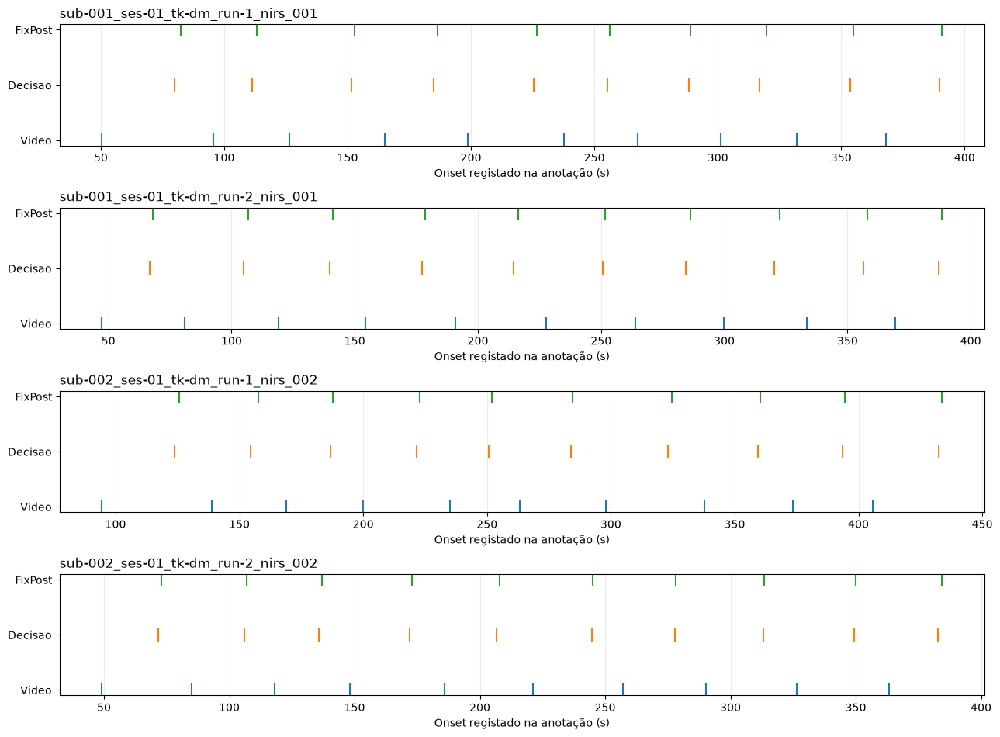


Objetos disponíveis em piloto_runs[(sujeito, run)].
Os ficheiros e os sinais originais foram preservados.
Não foram aplicados filtros ou critérios SCI.
Não foram criadas épocas nem ajustado GLM.
Nenhum ficheiro de resultados foi escrito.

As quatro runs passaram as verificações estruturais.
Isto não valida ainda a qualidade ótica, a identidade dos CSV ou a precisão temporal.

Etapa 2 concluída.


In [2]:
# ============================================================
# ETAPA 2 — LEITURA E INSPEÇÃO INICIAL DAS QUATRO RUNS
# ============================================================

import mne
import numpy as np
import matplotlib.pyplot as plt

from collections import Counter

N_ENSAIOS_ESPERADOS_PILOTO = 10

MARCADORES_PRINCIPAIS_PILOTO = {
    "120": "Video",
    "130": "Decisao",
    "150": "FixPost",
}

if not (
    df_inventario_piloto["estado"] == "LOCALIZADO"
).all():
    raise RuntimeError(
        "O inventário contém referências por resolver."
    )

# Estes dicionários passam a conter os dados desta etapa.
piloto_runs = {}
piloto_tabelas_canais = {}
piloto_tabelas_eventos = {}

registos_leitura_piloto = []


def codigo_marcador_piloto(descricao):
    """Interpretar códigos inteiros sem alterar as anotações."""
    texto = str(descricao).strip()

    try:
        numero = float(texto)
    except ValueError:
        return texto

    if np.isfinite(numero) and numero.is_integer():
        return str(int(numero))

    return texto


for _, entrada in df_inventario_piloto.iterrows():
    sujeito = entrada["sujeito"]
    numero_run = int(entrada["run"])
    chave = (sujeito, numero_run)

    print(f"\nA ler {sujeito} — run {numero_run}...")

    resumo = {
        "sujeito": sujeito,
        "run": numero_run,
        "estado": "ERRO",
        "erro": "",
    }

    try:
        # ----------------------------------------------------
        # 2.1 Ler o SNIRF
        # ----------------------------------------------------

        raw_piloto = mne.io.read_raw_snirf(
            entrada["caminho_snirf"],
            preload=True,
            verbose=False,
        )

        tipos = raw_piloto.get_channel_types()

        if not tipos or any(
            tipo != "fnirs_cw_amplitude"
            for tipo in tipos
        ):
            raise RuntimeError(
                "O SNIRF não contém exclusivamente "
                "intensidade ótica contínua."
            )

        distancias_m = (
            mne.preprocessing.nirs.source_detector_distances(
                raw_piloto.info
            )
        )

        if (
            not np.isfinite(distancias_m).all()
            or np.any(distancias_m <= 0)
        ):
            raise RuntimeError(
                "Existem distâncias fonte–detetor inválidas."
            )

        tabela_canais = pd.DataFrame({
            "canal": raw_piloto.ch_names,
            "tipo": tipos,
            "par": [
                nome.split()[0]
                for nome in raw_piloto.ch_names
            ],
            "comprimento_onda_nm": [
                float(canal["loc"][9])
                for canal in raw_piloto.info["chs"]
            ],
            "distancia_mm": distancias_m * 1000,
            "mau_previamente": [
                nome in raw_piloto.info["bads"]
                for nome in raw_piloto.ch_names
            ],
        })

        for par, grupo in tabela_canais.groupby("par"):
            if (
                len(grupo) != 2
                or not np.isfinite(
                    grupo["comprimento_onda_nm"]
                ).all()
                or grupo["comprimento_onda_nm"].nunique() != 2
            ):
                raise RuntimeError(
                    f"O par {par} não apresenta "
                    "duas séries com comprimentos de onda distintos."
                )

        # ----------------------------------------------------
        # 2.2 Inspecionar os eventos originais
        # ----------------------------------------------------

        tabela_eventos = pd.DataFrame({
            "onset_s": raw_piloto.annotations.onset,
            "duracao_s": raw_piloto.annotations.duration,
            "descricao_original": (
                raw_piloto.annotations.description
            ),
        })

        tabela_eventos["codigo_interpretado"] = (
            tabela_eventos["descricao_original"]
            .map(codigo_marcador_piloto)
        )

        contagens = Counter(
            tabela_eventos["codigo_interpretado"]
        )

        for codigo in MARCADORES_PRINCIPAIS_PILOTO:
            if contagens[codigo] != N_ENSAIOS_ESPERADOS_PILOTO:
                raise RuntimeError(
                    f"Marcador {codigo}: encontrados "
                    f"{contagens[codigo]}, esperados "
                    f"{N_ENSAIOS_ESPERADOS_PILOTO}."
                )

        eventos_interesse = (
            tabela_eventos.loc[
                tabela_eventos["codigo_interpretado"].isin(
                    ["120", "130"]
                )
            ]
            .sort_values("onset_s", kind="stable")
        )

        sequencia_esperada = np.tile(
            ["120", "130"],
            N_ENSAIOS_ESPERADOS_PILOTO,
        )

        if not np.array_equal(
            eventos_interesse["codigo_interpretado"].to_numpy(),
            sequencia_esperada,
        ):
            raise RuntimeError(
                "Os eventos não alternam vídeo → decisão."
            )

        if np.any(
            np.diff(eventos_interesse["onset_s"].to_numpy()) <= 0
        ):
            raise RuntimeError(
                "Existem onsets coincidentes ou fora de ordem."
            )

        # ----------------------------------------------------
        # 2.3 Ler o CSV comportamental
        # ----------------------------------------------------

        try:
            comportamento_piloto = pd.read_csv(
                entrada["csv_candidato"],
                encoding="utf-8-sig",
                sep=None,
                engine="python",
            )
        except UnicodeDecodeError:
            comportamento_piloto = pd.read_csv(
                entrada["csv_candidato"],
                encoding="cp1252",
                sep=None,
                engine="python",
            )

        colunas_necessarias = [
            "videos",
            "thisTrialN",
            "corrAns",
            "key_resp.keys",
            "key_resp.corr",
            "key_resp.rt",
        ]

        em_falta = [
            coluna
            for coluna in colunas_necessarias
            if coluna not in comportamento_piloto.columns
        ]

        if em_falta:
            raise RuntimeError(
                f"Colunas comportamentais ausentes: {em_falta}"
            )

        mascara_ensaios = (
            comportamento_piloto["videos"]
            .astype("string")
            .str.contains(
                r"\.(?:mp4|avi|mov|mkv)",
                case=False,
                regex=True,
                na=False,
            )
        )

        ensaios_piloto = (
            comportamento_piloto.loc[mascara_ensaios]
            .copy()
        )

        ensaios_piloto["thisTrialN"] = pd.to_numeric(
            ensaios_piloto["thisTrialN"],
            errors="coerce",
        )

        ensaios_piloto = (
            ensaios_piloto
            .sort_values("thisTrialN")
            .reset_index(drop=True)
        )

        if not np.array_equal(
            ensaios_piloto["thisTrialN"].to_numpy(),
            np.arange(N_ENSAIOS_ESPERADOS_PILOTO),
        ):
            raise RuntimeError(
                "Os ensaios do CSV não correspondem "
                "à sequência esperada de 0 a 9."
            )

        identificadores_csv = {}

        for coluna in ("participant", "session", "expName"):
            if coluna in comportamento_piloto.columns:
                identificadores_csv[coluna] = (
                    comportamento_piloto[coluna]
                    .dropna()
                    .astype(str)
                    .unique()
                    .tolist()
                )

        # ----------------------------------------------------
        # 2.4 Preservar os objetos por participante/run
        # ----------------------------------------------------

        piloto_runs[chave] = {
            "id_gravacao": entrada["id_gravacao"],
            "raw_intensidade": raw_piloto,
            "comportamento_original": comportamento_piloto,
            "ensaios_comportamentais": ensaios_piloto,
            "identificadores_csv": identificadores_csv,
            "caminho_snirf": entrada["caminho_snirf"],
            "caminho_csv": entrada["csv_candidato"],
            "pasta_saida_prevista": entrada["pasta_saida_prevista"],
        }

        piloto_tabelas_canais[chave] = tabela_canais
        piloto_tabelas_eventos[chave] = tabela_eventos

        resumo.update({
            "estado": "LEITURA_OK",
            "fs_hz": float(raw_piloto.info["sfreq"]),
            "n_amostras": int(raw_piloto.n_times),
            "tempo_final_relativo_s": float(raw_piloto.times[-1]),
            "n_series_oticas": len(raw_piloto.ch_names),
            "n_pares": int(tabela_canais["par"].nunique()),
            "n_video": contagens["120"],
            "n_decisao": contagens["130"],
            "n_fixpost": contagens["150"],
            "n_marcadores_resposta": sum(
                contagens[codigo]
                for codigo in ("140", "141", "142", "143")
            ),
            "n_ensaios_csv": len(ensaios_piloto),
        })

        print(f"  Identificadores internos do CSV: {identificadores_csv}")
        print(f"  Contagens de todos os marcadores: {dict(contagens)}")

    except Exception as erro:
        resumo["erro"] = (
            f"{type(erro).__name__}: {erro}"
        )
        print(f"  ERRO: {resumo['erro']}")

    registos_leitura_piloto.append(resumo)


# ------------------------------------------------------------
# 2.5 Resumo das quatro runs
# ------------------------------------------------------------

df_leitura_piloto = pd.DataFrame(
    registos_leitura_piloto
)

print("\n" + "=" * 70)
print("PILOTO DM — LEITURA E INSPEÇÃO INICIAL")
print("=" * 70)

print(
    df_leitura_piloto.to_string(
        index=False,
        float_format=lambda valor: f"{valor:.4f}",
    )
)


# ------------------------------------------------------------
# 2.6 Cronologia dos marcadores principais
# ------------------------------------------------------------

if piloto_runs:
    fig_eventos_piloto, eixos_eventos_piloto = plt.subplots(
        len(piloto_runs),
        1,
        figsize=(13, 2.4 * len(piloto_runs)),
        squeeze=False,
    )

    cores_eventos = {
        "120": "tab:blue",
        "130": "tab:orange",
        "150": "tab:green",
    }

    for ax, (chave, objetos) in zip(
        eixos_eventos_piloto[:, 0],
        piloto_runs.items(),
    ):
        tabela = piloto_tabelas_eventos[chave]

        for posicao, (codigo, nome) in enumerate(
            MARCADORES_PRINCIPAIS_PILOTO.items()
        ):
            onsets = tabela.loc[
                tabela["codigo_interpretado"] == codigo,
                "onset_s",
            ]

            ax.scatter(
                onsets,
                np.full(len(onsets), posicao),
                marker="|",
                s=180,
                color=cores_eventos[codigo],
            )

        ax.set_yticks(
            range(len(MARCADORES_PRINCIPAIS_PILOTO)),
            list(MARCADORES_PRINCIPAIS_PILOTO.values()),
        )

        ax.set_title(objetos["id_gravacao"], loc="left")
        ax.set_xlabel("Onset registado na anotação (s)")
        ax.grid(axis="x", alpha=0.25)

    fig_eventos_piloto.tight_layout()
    plt.show()

print("\nObjetos disponíveis em piloto_runs[(sujeito, run)].")
print("Os ficheiros e os sinais originais foram preservados.")
print("Não foram aplicados filtros ou critérios SCI.")
print("Não foram criadas épocas nem ajustado GLM.")
print("Nenhum ficheiro de resultados foi escrito.")

if (df_leitura_piloto["estado"] != "LEITURA_OK").any():
    print(
        "\nExistem runs com erros. "
        "Não avançar para o processamento antes de os rever."
    )
else:
    print(
        "\nAs quatro runs passaram as verificações estruturais."
    )
    print(
        "Isto não valida ainda a qualidade ótica, "
        "a identidade dos CSV ou a precisão temporal."
    )

print("\nEtapa 2 concluída.")

## Etapa 3 — Conversão da intensidade para densidade ótica

### Objetivo
Converter a intensidade luminosa registada em densidade ótica,
preservando os sinais originais.

### Verificação antes da conversão
Contar, por canal:
- Valores não finitos.
- Valores iguais a zero.
- Valores negativos.

Se alguma run apresentar estes valores, interromper a etapa
antes de converter qualquer uma das runs.

Não substituir ou corrigir automaticamente valores inválidos.

### Conversão
Utilizar a função optical_density do MNE.

Manter:
- Canais e respetiva ordem.
- Número de amostras.
- Frequência de amostragem.
- Anotações e marcações de canais maus.

### Visualização
Apresentar os dois comprimentos de onda do primeiro par
de cada run, apenas como inspeção ilustrativa.

Esta visualização não valida todos os canais.

### Resultados guardados
Por participante e run:
- Verificação dos valores de intensidade.
- Sinal em densidade ótica.
- Parâmetros da conversão.

A reexecução atualiza apenas os outputs desta etapa,
na pasta da nova versão piloto.

### Nesta etapa
Não calcular SCI.
Não corrigir movimento.
Não aplicar regressão de canais curtos.
Não converter para HbO/HbR.
Não filtrar nem criar épocas.

VERIFICAÇÃO DA INTENSIDADE ÓTICA
sujeito  run  n_series  n_nao_finitos  n_zeros  n_negativos
sub-001    1        56              0        0            0
sub-001    2        56              0        0            0
sub-002    1        56              0        0            0
sub-002    2        56              0        0            0

A converter sub-001 — run 1...

A converter sub-001 — run 2...

A converter sub-002 — run 1...

A converter sub-002 — run 2...


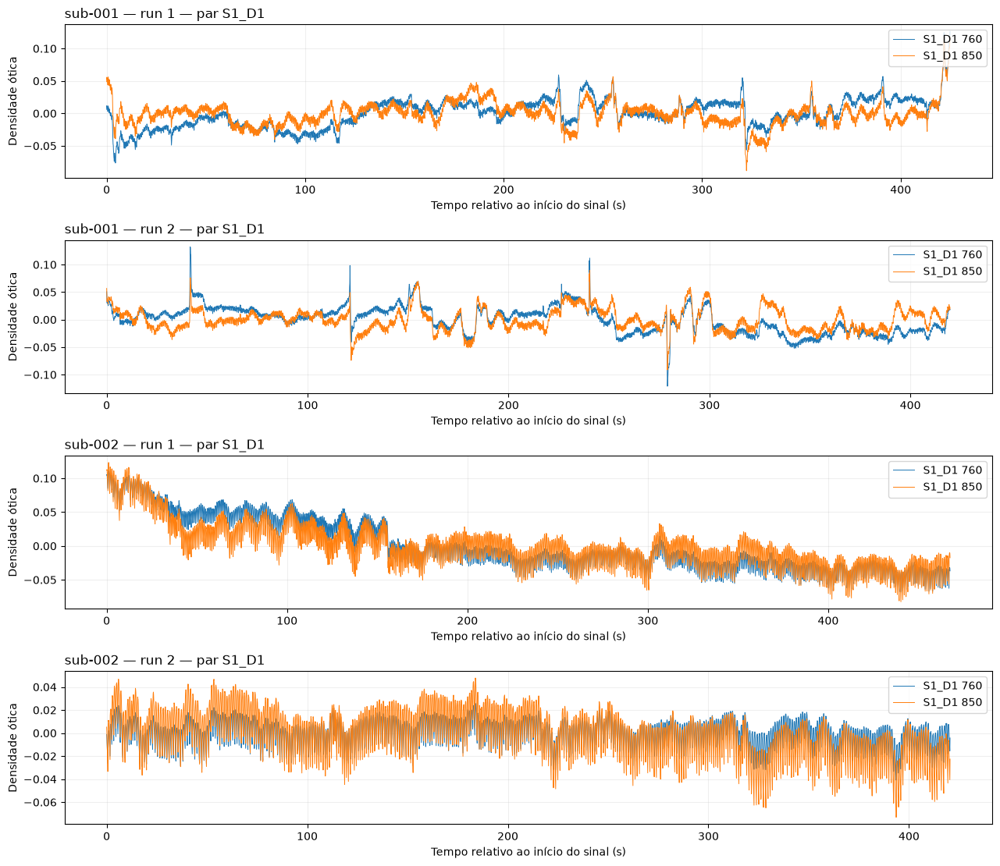


CONVERSÃO PARA DENSIDADE ÓTICA CONCLUÍDA
sujeito  run  n_series_od  n_amostras   fs_hz  valores_finitos  canais_preservados  anotacoes_preservadas
sub-001    1           56        4323 10.1725             True                True                   True
sub-001    2           56        4271 10.1725             True                True                   True
sub-002    1           56        4757 10.1725             True                True                   True
sub-002    2           56        4278 10.1725             True                True                   True

Objetos disponíveis: piloto_od[(sujeito, run)].
Os objetos de intensidade em piloto_runs foram preservados.
Outputs guardados nas pastas da nova versão piloto.
Não foram aplicados SCI, TDDR, SSR ou filtragem.
A conversão não demonstra, por si só, boa qualidade ótica.

Etapa 3 concluída.


In [3]:
# ============================================================
# ETAPA 3 — CONVERSÃO PARA DENSIDADE ÓTICA
# ============================================================

import json
from importlib.metadata import version

if (
    len(piloto_runs) != len(df_inventario_piloto)
    or not (df_leitura_piloto["estado"] == "LEITURA_OK").all()
):
    raise RuntimeError(
        "As quatro runs devem passar a Etapa 2 antes de continuar."
    )

piloto_qc_intensidade = {}
registos_resumo_intensidade = []

# ------------------------------------------------------------
# 3.1 Verificar as quatro runs antes de converter
# ------------------------------------------------------------

for chave, objetos in piloto_runs.items():
    raw_entrada = objetos["raw_intensidade"]
    intensidade = raw_entrada.get_data()

    linhas_qc = []

    for indice, canal in enumerate(raw_entrada.ch_names):
        valores = intensidade[indice]
        finitos = valores[np.isfinite(valores)]

        linhas_qc.append({
            "canal": canal,
            "n_nao_finitos": int(
                (~np.isfinite(valores)).sum()
            ),
            "n_zeros": int((valores == 0).sum()),
            "n_negativos": int((valores < 0).sum()),
            "minimo_finito": (
                float(finitos.min()) if len(finitos) else np.nan
            ),
            "maximo_finito": (
                float(finitos.max()) if len(finitos) else np.nan
            ),
        })

    tabela_qc = pd.DataFrame(linhas_qc)
    piloto_qc_intensidade[chave] = tabela_qc

    registos_resumo_intensidade.append({
        "sujeito": chave[0],
        "run": chave[1],
        "n_series": len(raw_entrada.ch_names),
        "n_nao_finitos": int(
            tabela_qc["n_nao_finitos"].sum()
        ),
        "n_zeros": int(tabela_qc["n_zeros"].sum()),
        "n_negativos": int(
            tabela_qc["n_negativos"].sum()
        ),
    })

df_intensidade_piloto = pd.DataFrame(
    registos_resumo_intensidade
)

print("=" * 70)
print("VERIFICAÇÃO DA INTENSIDADE ÓTICA")
print("=" * 70)
print(df_intensidade_piloto.to_string(index=False))

problemas_intensidade = (
    df_intensidade_piloto[
        ["n_nao_finitos", "n_zeros", "n_negativos"]
    ] > 0
).any(axis=1)

if problemas_intensidade.any():
    for _, problema in df_intensidade_piloto.loc[
        problemas_intensidade
    ].iterrows():
        chave = (problema["sujeito"], int(problema["run"]))
        tabela = piloto_qc_intensidade[chave]

        canais_problematicos = (
            tabela[
                ["n_nao_finitos", "n_zeros", "n_negativos"]
            ] > 0
        ).any(axis=1)

        print(f"\nCanais a rever — {chave}:")
        print(
            tabela.loc[canais_problematicos].to_string(index=False)
        )

    raise RuntimeError(
        "Foram encontrados valores inválidos. "
        "Nenhuma run foi convertida nesta execução."
    )


# ------------------------------------------------------------
# 3.2 Converter e verificar, sem escrever ficheiros ainda
# ------------------------------------------------------------

piloto_od = {}
registos_resumo_od = []

for chave, objetos in piloto_runs.items():
    raw_entrada = objetos["raw_intensidade"]

    print(f"\nA converter {chave[0]} — run {chave[1]}...")

    # A função cria uma cópia; o objeto de intensidade é preservado.
    raw_od_piloto = mne.preprocessing.nirs.optical_density(
        raw_entrada,
        verbose=False,
    )

    if (
        raw_od_piloto.ch_names != raw_entrada.ch_names
        or raw_od_piloto.n_times != raw_entrada.n_times
        or raw_od_piloto.info["sfreq"] != raw_entrada.info["sfreq"]
    ):
        raise RuntimeError(
            f"Canais ou grelha temporal alterados em {chave}."
        )

    if raw_od_piloto.info["bads"] != raw_entrada.info["bads"]:
        raise RuntimeError(
            f"A marcação dos canais maus mudou em {chave}."
        )

    anotacoes_iguais = (
        np.array_equal(
            raw_od_piloto.annotations.onset,
            raw_entrada.annotations.onset,
        )
        and np.array_equal(
            raw_od_piloto.annotations.duration,
            raw_entrada.annotations.duration,
        )
        and np.array_equal(
            raw_od_piloto.annotations.description,
            raw_entrada.annotations.description,
        )
        and (
            raw_od_piloto.annotations.orig_time
            == raw_entrada.annotations.orig_time
        )
    )

    if not anotacoes_iguais:
        raise RuntimeError(
            f"As anotações mudaram em {chave}."
        )

    if not all(
        tipo == "fnirs_od"
        for tipo in raw_od_piloto.get_channel_types()
    ):
        raise RuntimeError(
            f"Tipos de canal inesperados após conversão em {chave}."
        )

    valores_od = raw_od_piloto.get_data()

    if not np.isfinite(valores_od).all():
        raise RuntimeError(
            f"Existem valores não finitos após conversão em {chave}."
        )

    piloto_od[chave] = raw_od_piloto

    registos_resumo_od.append({
        "sujeito": chave[0],
        "run": chave[1],
        "n_series_od": len(raw_od_piloto.ch_names),
        "n_amostras": int(raw_od_piloto.n_times),
        "fs_hz": float(raw_od_piloto.info["sfreq"]),
        "valores_finitos": True,
        "canais_preservados": True,
        "anotacoes_preservadas": True,
    })


# ------------------------------------------------------------
# 3.3 Guardar os resultados na nova versão piloto
# ------------------------------------------------------------

for chave, raw_od_piloto in piloto_od.items():
    objetos = piloto_runs[chave]
    id_gravacao = objetos["id_gravacao"]
    pasta_saida = Path(objetos["pasta_saida_prevista"])

    pasta_saida.mkdir(parents=True, exist_ok=True)

    piloto_qc_intensidade[chave].to_csv(
        pasta_saida / f"{id_gravacao}_intensity_value_check.csv",
        index=False,
        encoding="utf-8-sig",
    )

    raw_od_piloto.save(
        pasta_saida / f"{id_gravacao}_od_raw.fif",
        overwrite=True,
        fmt="double",
        verbose=False,
    )

    parametros_od = {
        "id_gravacao": id_gravacao,
        "pipeline_version": VERSAO_PIPELINE_PILOTO,
        "etapa": 3,
        "metodo": "mne.preprocessing.nirs.optical_density",
        "mne_version": version("mne"),
        "caminho_snirf_origem": objetos["caminho_snirf"],
        "n_series": len(raw_od_piloto.ch_names),
        "n_amostras": int(raw_od_piloto.n_times),
        "sfreq_hz": float(raw_od_piloto.info["sfreq"]),
        "valores_nao_positivos_na_entrada": 0,
        "valores_nao_finitos_na_entrada": 0,
        "valores_finitos_na_saida": True,
        "anotacoes_preservadas": True,
        "bads": list(raw_od_piloto.info["bads"]),
        "sci_calculado": False,
        "tddr_aplicado": False,
        "ssr_aplicada": False,
        "filtro_hemodinamico_aplicado": False,
    }

    (
        pasta_saida / f"{id_gravacao}_od_parameters.json"
    ).write_text(
        json.dumps(
            parametros_od,
            ensure_ascii=False,
            indent=2,
        ),
        encoding="utf-8",
    )


# ------------------------------------------------------------
# 3.4 Inspeção ilustrativa do primeiro par de cada run
# ------------------------------------------------------------

fig_od_piloto, eixos_od_piloto = plt.subplots(
    len(piloto_od),
    1,
    figsize=(13, 2.8 * len(piloto_od)),
    squeeze=False,
)

for ax, (chave, raw_od_piloto) in zip(
    eixos_od_piloto[:, 0],
    piloto_od.items(),
):
    tabela_canais = piloto_tabelas_canais[chave]
    primeiro_par = tabela_canais["par"].iloc[0]

    indices_par = np.flatnonzero(
        tabela_canais["par"].to_numpy() == primeiro_par
    )

    dados_par = raw_od_piloto.get_data(picks=indices_par)

    for indice_local, indice_canal in enumerate(indices_par):
        ax.plot(
            raw_od_piloto.times,
            dados_par[indice_local],
            linewidth=0.7,
            label=raw_od_piloto.ch_names[indice_canal],
        )

    ax.set_title(
        f"{chave[0]} — run {chave[1]} — par {primeiro_par}",
        loc="left",
    )
    ax.set_xlabel("Tempo relativo ao início do sinal (s)")
    ax.set_ylabel("Densidade ótica")
    ax.grid(alpha=0.2)
    ax.legend(loc="upper right")

fig_od_piloto.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3.5 Resumo
# ------------------------------------------------------------

df_od_piloto = pd.DataFrame(registos_resumo_od)

print("\n" + "=" * 70)
print("CONVERSÃO PARA DENSIDADE ÓTICA CONCLUÍDA")
print("=" * 70)

print(
    df_od_piloto.to_string(
        index=False,
        float_format=lambda valor: f"{valor:.4f}",
    )
)

print("\nObjetos disponíveis: piloto_od[(sujeito, run)].")
print("Os objetos de intensidade em piloto_runs foram preservados.")
print("Outputs guardados nas pastas da nova versão piloto.")
print("Não foram aplicados SCI, TDDR, SSR ou filtragem.")
print("A conversão não demonstra, por si só, boa qualidade ótica.")
print("\nEtapa 3 concluída.")

## Etapa 4 — Qualidade dos canais pelo Scalp Coupling Index

### Objetivo
Avaliar o acoplamento ótico nas quatro runs e marcar
os pares que não cumprem o critério definido.

### Parâmetros
- SCI calculado sobre a gravação completa.
- Banda: 0,7–1,5 Hz.
- Limiar: SCI inferior a 0,7.
- Valores não finitos também são sinalizados.

Este limiar é uma escolha desta pipeline,
não uma garantia universal de qualidade.

### Marcação por par
Se uma das séries de um par for sinalizada,
marcar o par fonte–detetor completo.

Preservar as marcações de canais maus já existentes.
Os canais são marcados, não removidos.

### Classificação geométrica
- Curto: distância inferior a 10 mm.
- Longo: distância superior a 15 mm.
- Intermédio: restantes distâncias.

Esta classificação não altera o limiar SCI.

A disponibilidade de canais curtos para eventual SSR
será avaliada separadamente em cada run.

### Preservação
- piloto_od: sinal anterior, preservado.
- piloto_od_qc: cópia com a marcação de qualidade.

### Resultados guardados
Por participante e run:
- SCI por série ótica.
- Resumo por par.
- Sinal com canais maus assinalados.
- Histograma.
- Parâmetros.

### Limitações
Um SCI global não avalia a qualidade em cada instante.
Uma run pode conter segmentos problemáticos mesmo
quando o SCI global do canal é elevado.

### Nesta etapa
Não remover canais.
Não aplicar TDDR, SSR ou filtro hemodinâmico.
Não criar épocas ou ajustar modelos.


A calcular SCI: sub-001 — run 1...


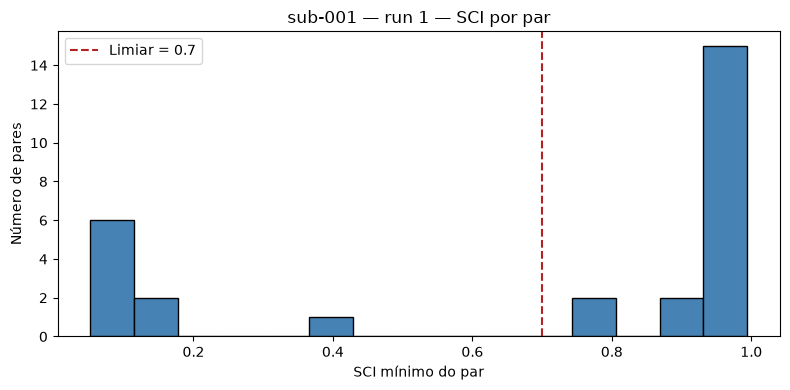


A calcular SCI: sub-001 — run 2...


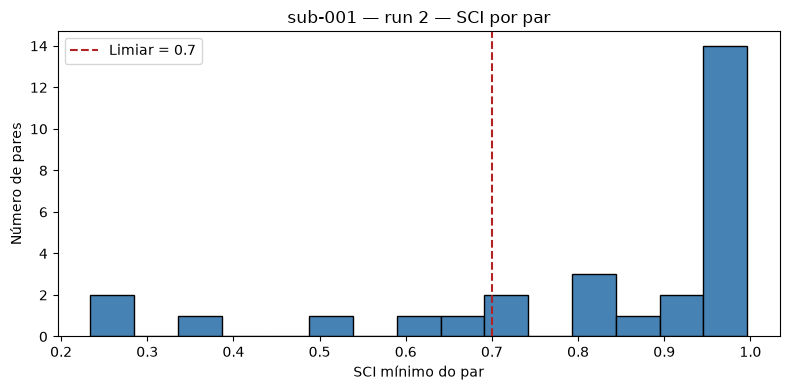


A calcular SCI: sub-002 — run 1...


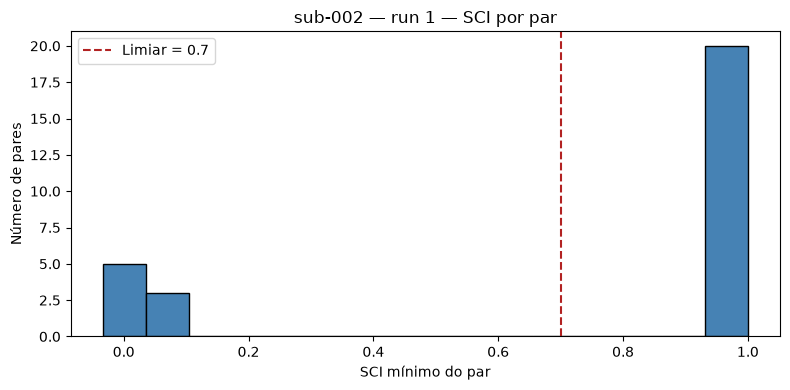


A calcular SCI: sub-002 — run 2...


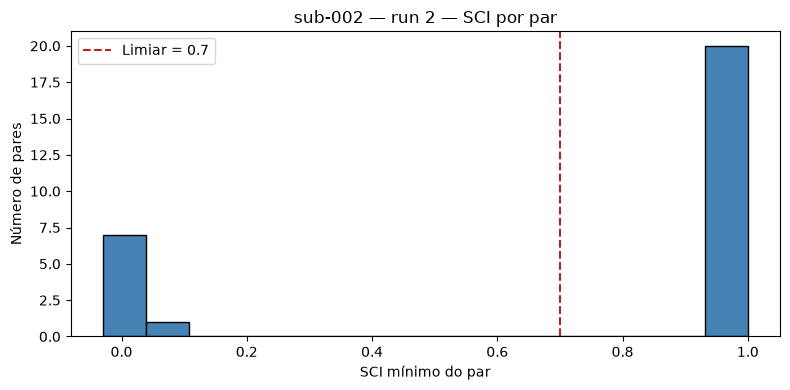


QUALIDADE ÓTICA — SCI
sujeito  run  n_pares  n_pares_maus  n_series_maus  n_SCI_nao_finitos  n_curtos  n_curtos_validos  n_longos  n_longos_validos
sub-001    1       28             9             18                  0         8                 0        20                19
sub-001    2       28             6             12                  0         8                 3        20                19
sub-002    1       28             8             16                  0         8                 0        20                20
sub-002    2       28             8             16                  0         8                 0        20                20

--- sub-001 | run 1 ---
   par  distancia_mm tipo_distancia  SCI_min  SCI_nao_finito  marcado_mau
 S1_D1       30.5904          longo   0.9703           False        False
 S1_D2       30.4793          longo   0.9791           False        False
 S1_D8        8.7017          curto   0.4207           False         True
 S2_D1       35.9575      

In [4]:
# ============================================================
# ETAPA 4 — CONTROLO DE QUALIDADE PELO SCI
# ============================================================

LIMIAR_SCI_PILOTO = 0.7
SCI_LOW_HZ_PILOTO = 0.7
SCI_HIGH_HZ_PILOTO = 1.5

DISTANCIA_MAX_CURTA_M_PILOTO = 0.010
DISTANCIA_MIN_LONGA_M_PILOTO = 0.015

if set(piloto_od) != set(piloto_runs):
    raise RuntimeError(
        "Faltam objetos de densidade ótica para alguma run."
    )

piloto_od_qc = {}
piloto_sci_series = {}
piloto_sci_pares = {}

registos_resumo_sci = []

for chave, raw_od_entrada in piloto_od.items():
    objetos = piloto_runs[chave]
    id_gravacao = objetos["id_gravacao"]

    print(f"\nA calcular SCI: {chave[0]} — run {chave[1]}...")

    if not all(
        tipo == "fnirs_od"
        for tipo in raw_od_entrada.get_channel_types()
    ):
        raise RuntimeError(
            f"A entrada não contém apenas densidade ótica: {chave}"
        )

    bads_anteriores = list(raw_od_entrada.info["bads"])

    # Cópia apenas para cálculo em todas as séries.
    # As marcações anteriores serão preservadas no resultado.
    raw_calculo_sci = raw_od_entrada.copy()
    raw_calculo_sci.info["bads"] = []

    sci = np.asarray(
        mne.preprocessing.nirs.scalp_coupling_index(
            raw_calculo_sci,
            l_freq=SCI_LOW_HZ_PILOTO,
            h_freq=SCI_HIGH_HZ_PILOTO,
            l_trans_bandwidth=0.3,
            h_trans_bandwidth=0.3,
            verbose=False,
        ),
        dtype=float,
    )

    if sci.shape != (len(raw_od_entrada.ch_names),):
        raise RuntimeError(
            f"O número de valores SCI não corresponde aos canais: {chave}"
        )

    distancias_m = (
        mne.preprocessing.nirs.source_detector_distances(
            raw_od_entrada.info
        )
    )

    tabela_sci = pd.DataFrame({
        "canal": raw_od_entrada.ch_names,
        "par": [
            nome.split()[0]
            for nome in raw_od_entrada.ch_names
        ],
        "SCI": sci,
        "distancia_mm": distancias_m * 1000,
        "mau_previamente": [
            nome in bads_anteriores
            for nome in raw_od_entrada.ch_names
        ],
    })

    tabela_sci["tipo_distancia"] = np.select(
        [
            distancias_m < DISTANCIA_MAX_CURTA_M_PILOTO,
            distancias_m > DISTANCIA_MIN_LONGA_M_PILOTO,
        ],
        ["curto", "longo"],
        default="intermedio",
    )

    tabela_sci["SCI_nao_finito"] = ~np.isfinite(sci)

    tabela_sci["SCI_abaixo_limiar"] = (
        np.isfinite(sci)
        & (sci < LIMIAR_SCI_PILOTO)
    )

    tabela_sci["sinalizado_SCI"] = (
        tabela_sci["SCI_nao_finito"]
        | tabela_sci["SCI_abaixo_limiar"]
    )

    pares_maus = set(
        tabela_sci.loc[
            tabela_sci["sinalizado_SCI"]
            | tabela_sci["mau_previamente"],
            "par",
        ]
    )

    tabela_sci["marcado_mau_final"] = (
        tabela_sci["par"].isin(pares_maus)
    )

    tabela_pares = (
        tabela_sci
        .groupby("par", sort=False)
        .agg(
            distancia_mm=("distancia_mm", "first"),
            tipo_distancia=("tipo_distancia", "first"),
            n_series=("canal", "size"),
            SCI_min=("SCI", "min"),
            SCI_max=("SCI", "max"),
            SCI_nao_finito=("SCI_nao_finito", "any"),
            mau_previamente=("mau_previamente", "any"),
            sinalizado_SCI=("sinalizado_SCI", "any"),
            marcado_mau=("marcado_mau_final", "any"),
        )
        .reset_index()
    )

    tabela_pares["valido"] = ~tabela_pares["marcado_mau"]

    # Aplicar as marcações a outra cópia, sem alterar a entrada.
    raw_qc = raw_od_entrada.copy()

    raw_qc.info["bads"] = tabela_sci.loc[
        tabela_sci["marcado_mau_final"],
        "canal",
    ].tolist()

    if (
        raw_qc.ch_names != raw_od_entrada.ch_names
        or raw_qc.n_times != raw_od_entrada.n_times
    ):
        raise RuntimeError(
            f"Canais ou amostras alterados na marcação: {chave}"
        )

    if not set(bads_anteriores).issubset(raw_qc.info["bads"]):
        raise RuntimeError(
            f"Foram perdidas marcações anteriores: {chave}"
        )

    if not np.array_equal(
        raw_qc.get_data(),
        raw_od_entrada.get_data(),
    ):
        raise RuntimeError(
            f"O sinal foi alterado durante a marcação: {chave}"
        )

    piloto_od_qc[chave] = raw_qc
    piloto_sci_series[chave] = tabela_sci
    piloto_sci_pares[chave] = tabela_pares

    curtos = tabela_pares["tipo_distancia"] == "curto"
    longos = tabela_pares["tipo_distancia"] == "longo"
    validos = tabela_pares["valido"]

    resumo = {
        "sujeito": chave[0],
        "run": chave[1],
        "n_pares": len(tabela_pares),
        "n_pares_maus": int(tabela_pares["marcado_mau"].sum()),
        "n_series_maus": len(raw_qc.info["bads"]),
        "n_SCI_nao_finitos": int(
            tabela_sci["SCI_nao_finito"].sum()
        ),
        "n_curtos": int(curtos.sum()),
        "n_curtos_validos": int((curtos & validos).sum()),
        "n_longos": int(longos.sum()),
        "n_longos_validos": int((longos & validos).sum()),
    }

    registos_resumo_sci.append(resumo)

    # --------------------------------------------------------
    # Guardar resultados por participante/run
    # --------------------------------------------------------

    pasta_saida = Path(objetos["pasta_saida_prevista"])

    tabela_sci.to_csv(
        pasta_saida / f"{id_gravacao}_sci_channels.csv",
        index=False,
        encoding="utf-8-sig",
    )

    tabela_pares.to_csv(
        pasta_saida / f"{id_gravacao}_sci_pairs.csv",
        index=False,
        encoding="utf-8-sig",
    )

    raw_qc.save(
        pasta_saida / f"{id_gravacao}_od_qc_raw.fif",
        overwrite=True,
        fmt="double",
        verbose=False,
    )

    parametros_sci = {
        "id_gravacao": id_gravacao,
        "pipeline_version": VERSAO_PIPELINE_PILOTO,
        "etapa": 4,
        "mne_version": version("mne"),
        "limiar_SCI": LIMIAR_SCI_PILOTO,
        "banda_SCI_hz": [
            SCI_LOW_HZ_PILOTO,
            SCI_HIGH_HZ_PILOTO,
        ],
        "l_trans_bandwidth_hz": 0.3,
        "h_trans_bandwidth_hz": 0.3,
        "avaliacao": "gravacao completa",
        "criterio": "SCI abaixo do limiar ou nao finito",
        "marcacao": "par fonte-detetor completo",
        "curto_distancia_inferior_m": DISTANCIA_MAX_CURTA_M_PILOTO,
        "longo_distancia_superior_m": DISTANCIA_MIN_LONGA_M_PILOTO,
        "bads_anteriores": bads_anteriores,
        "bads_finais": list(raw_qc.info["bads"]),
        "resumo": resumo,
        "canais_removidos": False,
        "tddr_aplicado": False,
        "ssr_aplicada": False,
    }

    (
        pasta_saida / f"{id_gravacao}_sci_parameters.json"
    ).write_text(
        json.dumps(
            parametros_sci,
            ensure_ascii=False,
            indent=2,
        ),
        encoding="utf-8",
    )

    fig_sci, ax_sci = plt.subplots(figsize=(8, 4))

    valores_histograma = tabela_pares.loc[
        ~tabela_pares["SCI_nao_finito"],
        "SCI_min",
    ].to_numpy()

    if len(valores_histograma):
        ax_sci.hist(
            valores_histograma,
            bins=15,
            color="steelblue",
            edgecolor="black",
        )
    else:
        ax_sci.text(
            0.5, 0.5,
            "Sem pares com SCI finito",
            transform=ax_sci.transAxes,
            ha="center",
        )

    ax_sci.axvline(
        LIMIAR_SCI_PILOTO,
        color="firebrick",
        linestyle="--",
        label=f"Limiar = {LIMIAR_SCI_PILOTO}",
    )

    ax_sci.set(
        title=f"{chave[0]} — run {chave[1]} — SCI por par",
        xlabel="SCI mínimo do par",
        ylabel="Número de pares",
    )

    ax_sci.legend()
    fig_sci.tight_layout()

    fig_sci.savefig(
        pasta_saida / f"{id_gravacao}_sci_histogram.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()


# ------------------------------------------------------------
# 4.6 Resumo das quatro runs
# ------------------------------------------------------------

df_sci_piloto = pd.DataFrame(registos_resumo_sci)

print("\n" + "=" * 70)
print("QUALIDADE ÓTICA — SCI")
print("=" * 70)

print(df_sci_piloto.to_string(index=False))

for chave, tabela_pares in piloto_sci_pares.items():
    print(f"\n--- {chave[0]} | run {chave[1]} ---")
    print(
        tabela_pares[
            [
                "par",
                "distancia_mm",
                "tipo_distancia",
                "SCI_min",
                "SCI_nao_finito",
                "marcado_mau",
            ]
        ].to_string(
            index=False,
            float_format=lambda valor: f"{valor:.4f}",
        )
    )

print("\nObjetos seguintes: piloto_od_qc[(sujeito, run)].")
print("Os canais foram marcados, não removidos.")
print("Os objetos anteriores em piloto_od foram preservados.")
print("Resultados guardados nas pastas da versão piloto.")
print("Não foram aplicados TDDR, SSR ou filtro hemodinâmico.")

if (df_sci_piloto["n_longos_validos"] == 0).any():
    print(
        "\nATENÇÃO: existe pelo menos uma run sem pares longos válidos. "
        "Rever antes de avançar."
    )

print("\nEtapa 4 concluída.")

## Etapa 5 — Correção de movimento com TDDR

### Objetivo
Aplicar Temporal Derivative Distribution Repair à densidade
ótica, antes da conversão para HbO e HbR.

### Entrada
piloto_od_qc:
densidade ótica com as marcações de qualidade do SCI.

### Procedimento
Aplicar a implementação TDDR do MNE,
sem modificar os parâmetros internos do algoritmo.

Trabalhar sobre uma cópia de cada run.

### Preservação
Manter:
- Canais e respetiva ordem.
- Número de amostras e frequência de amostragem.
- Anotações.
- Marcações dos canais maus.

O TDDR não reclassifica canais maus como válidos.

### Visualização
Comparar antes e depois num par longo que seja válido
nas quatro runs.

Selecionar o primeiro par comum pela ordem da tabela,
não pelo aspeto da resposta.

Apresentar os dois comprimentos de onda separadamente.

### Verificações
- Dados finitos após a correção.
- Estrutura e anotações preservadas.
- Marcações de qualidade preservadas.

### Limitações
A execução sem erros não demonstra remoção completa
dos artefactos de movimento.

Uma curva mais lisa não é, por si só, mais válida.

A inspeção de um par não substitui a avaliação
dos restantes canais e segmentos.

### Resultados guardados
Por participante e run:
- Densidade ótica após TDDR.
- Figura antes/depois.
- Parâmetros e resumo.

### Nesta etapa
Não remover canais.
Não aplicar SSR.
Não converter para HbO/HbR.
Não aplicar filtro hemodinâmico ou criar épocas.

Par comum selecionado para inspeção: S1_D1

A aplicar TDDR: sub-001 — run 1...

A aplicar TDDR: sub-001 — run 2...

A aplicar TDDR: sub-002 — run 1...

A aplicar TDDR: sub-002 — run 2...


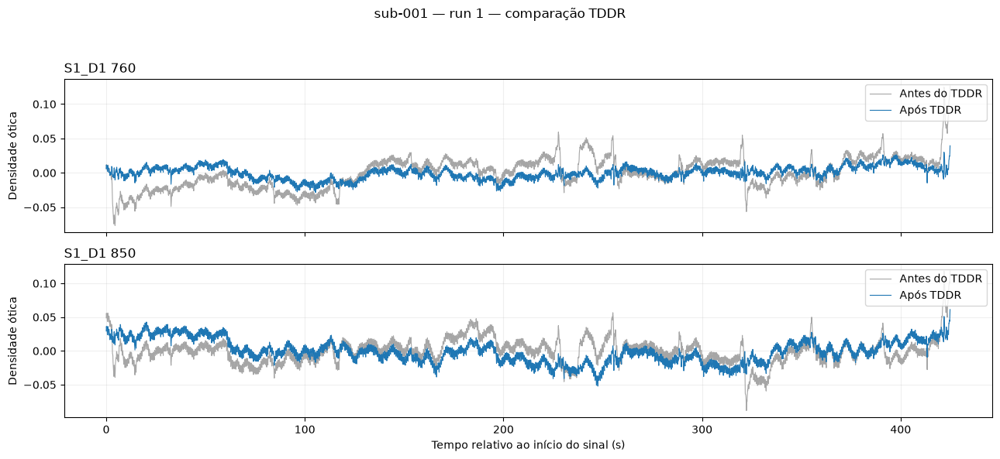

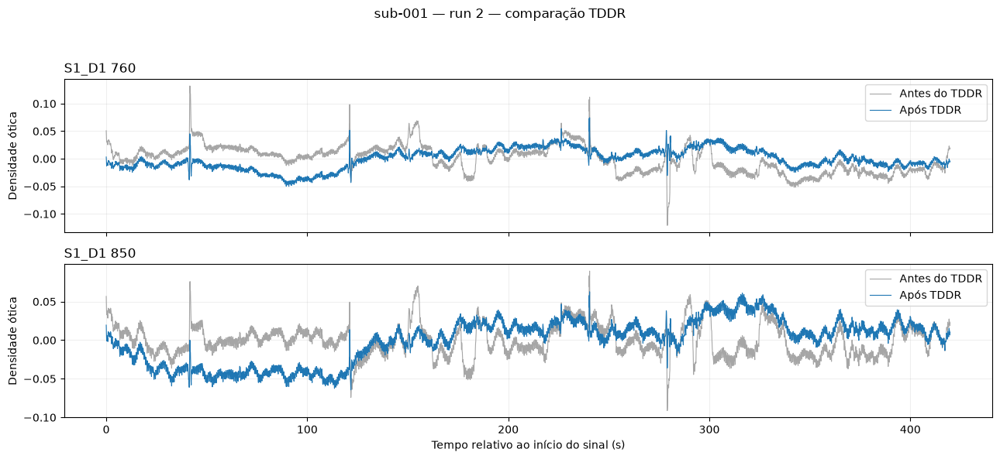

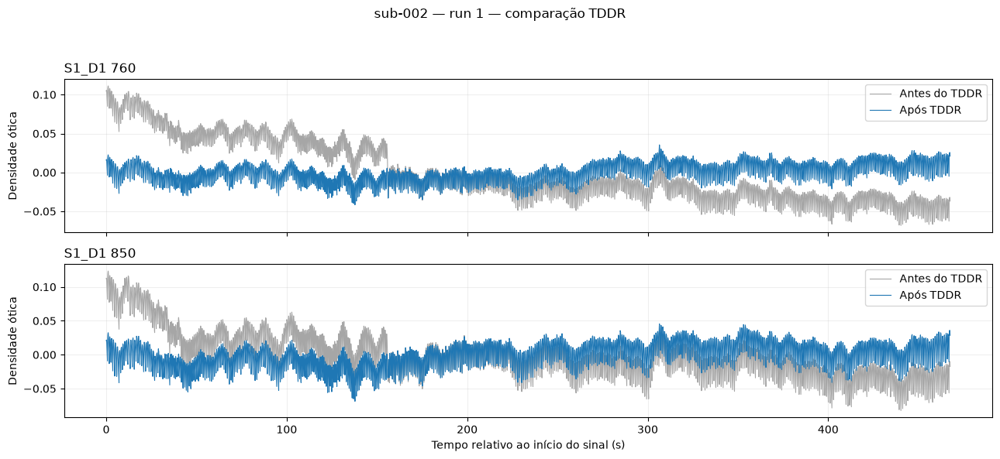

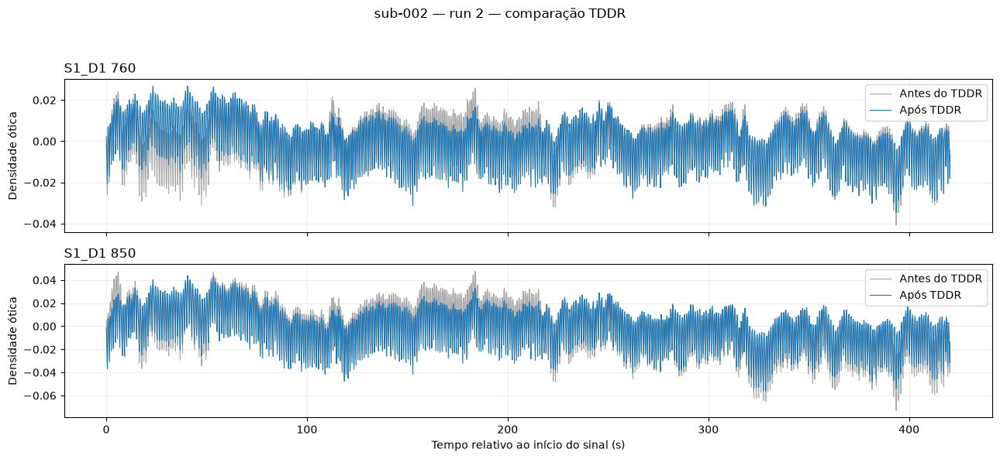


CORREÇÃO TDDR CONCLUÍDA
sujeito  run  n_series  n_series_nao_marcadas  n_amostras  valores_finitos  bads_preservados  anotacoes_preservadas
sub-001    1        56                     38        4323             True              True                   True
sub-001    2        56                     44        4271             True              True                   True
sub-002    1        56                     40        4757             True              True                   True
sub-002    2        56                     40        4278             True              True                   True

Par utilizado nas figuras: S1_D1

Objetos disponíveis: piloto_od_tddr[(sujeito, run)].
Os objetos anteriores em piloto_od_qc foram preservados.
Os canais maus continuam marcados.
Nenhum canal foi removido ou reclassificado.
Não foram aplicados SSR ou filtro hemodinâmico.
Não foram criadas épocas nem ajustados modelos.
Resultados guardados nas pastas da versão piloto.

Etapa 5 concluída.


In [6]:
# ============================================================
# ETAPA 5 — CORREÇÃO DE MOVIMENTO COM TDDR
# ============================================================

if set(piloto_od_qc) != set(piloto_runs):
    raise RuntimeError(
        "Faltam objetos com controlo SCI para alguma run."
    )

if (df_sci_piloto["n_longos_validos"] == 0).any():
    raise RuntimeError(
        "Existe uma run sem pares longos válidos. "
        "Rever antes de continuar."
    )


# ------------------------------------------------------------
# 5.1 Selecionar um par longo válido comum para visualização
# ------------------------------------------------------------

pares_longos_comuns_tddr = None

for chave, tabela_pares in piloto_sci_pares.items():
    pares_validos = set(
        tabela_pares.loc[
            (tabela_pares["tipo_distancia"] == "longo")
            & tabela_pares["valido"],
            "par",
        ]
    )

    if pares_longos_comuns_tddr is None:
        pares_longos_comuns_tddr = pares_validos
    else:
        pares_longos_comuns_tddr &= pares_validos

primeira_chave_tddr = next(iter(piloto_sci_pares))

ordem_pares_tddr = piloto_sci_pares[
    primeira_chave_tddr
]["par"].tolist()

par_visualizacao_tddr = next(
    (
        par
        for par in ordem_pares_tddr
        if par in pares_longos_comuns_tddr
    ),
    None,
)

print(
    "Par comum selecionado para inspeção: "
    f"{par_visualizacao_tddr}"
)

if par_visualizacao_tddr is None:
    print(
        "Não existe um par longo válido comum às quatro runs. "
        "A correção será verificada numericamente; "
        "a seleção das figuras terá de ser revista."
    )


# ------------------------------------------------------------
# 5.2 Aplicar TDDR e verificar todas as runs
# ------------------------------------------------------------

piloto_od_tddr = {}
registos_resumo_tddr = []

for chave, raw_entrada in piloto_od_qc.items():
    print(
        f"\nA aplicar TDDR: {chave[0]} — run {chave[1]}..."
    )

    if not all(
        tipo == "fnirs_od"
        for tipo in raw_entrada.get_channel_types()
    ):
        raise RuntimeError(
            f"A entrada não contém apenas densidade ótica: {chave}"
        )

    bads_antes = list(raw_entrada.info["bads"])

    raw_corrigido = (
        mne.preprocessing.nirs.temporal_derivative_distribution_repair(
            raw_entrada.copy(),
            verbose=False,
        )
    )

    if (
        raw_corrigido.ch_names != raw_entrada.ch_names
        or raw_corrigido.n_times != raw_entrada.n_times
        or raw_corrigido.info["sfreq"] != raw_entrada.info["sfreq"]
    ):
        raise RuntimeError(
            f"A estrutura do sinal mudou durante o TDDR: {chave}"
        )

    if raw_corrigido.info["bads"] != bads_antes:
        raise RuntimeError(
            f"A marcação dos canais maus mudou: {chave}"
        )

    anotacoes_preservadas = (
        np.array_equal(
            raw_corrigido.annotations.onset,
            raw_entrada.annotations.onset,
        )
        and np.array_equal(
            raw_corrigido.annotations.duration,
            raw_entrada.annotations.duration,
        )
        and np.array_equal(
            raw_corrigido.annotations.description,
            raw_entrada.annotations.description,
        )
        and (
            raw_corrigido.annotations.orig_time
            == raw_entrada.annotations.orig_time
        )
    )

    if not anotacoes_preservadas:
        raise RuntimeError(
            f"As anotações mudaram durante o TDDR: {chave}"
        )

    if not np.isfinite(raw_corrigido.get_data()).all():
        raise RuntimeError(
            f"Existem valores não finitos após TDDR: {chave}"
        )

    piloto_od_tddr[chave] = raw_corrigido

    registos_resumo_tddr.append({
        "sujeito": chave[0],
        "run": chave[1],
        "n_series": len(raw_corrigido.ch_names),
        "n_series_nao_marcadas": (
            len(raw_corrigido.ch_names)
            - len(raw_corrigido.info["bads"])
        ),
        "n_amostras": int(raw_corrigido.n_times),
        "valores_finitos": True,
        "bads_preservados": True,
        "anotacoes_preservadas": True,
    })


# ------------------------------------------------------------
# 5.3 Guardar resultados e comparações visuais
# ------------------------------------------------------------

for chave, raw_corrigido in piloto_od_tddr.items():
    objetos = piloto_runs[chave]
    raw_entrada = piloto_od_qc[chave]

    pasta_saida = Path(objetos["pasta_saida_prevista"])
    id_gravacao = objetos["id_gravacao"]

    caminho_tddr = (
        pasta_saida / f"{id_gravacao}_od_tddr_raw.fif"
    )

    raw_corrigido.save(
        caminho_tddr,
        overwrite=True,
        fmt="double",
        verbose=False,
    )

    if par_visualizacao_tddr is not None:
        indices_par = [
            indice
            for indice, nome in enumerate(raw_entrada.ch_names)
            if nome.split()[0] == par_visualizacao_tddr
        ]

        if len(indices_par) != 2:
            raise RuntimeError(
                f"O par de visualização não tem duas séries: {chave}"
            )

        dados_antes = raw_entrada.get_data(
            picks=indices_par
        )

        dados_depois = raw_corrigido.get_data(
            picks=indices_par
        )

        fig_tddr, eixos_tddr = plt.subplots(
            2,
            1,
            figsize=(13, 6),
            sharex=True,
        )

        for indice_local, (ax, indice_canal) in enumerate(
            zip(eixos_tddr, indices_par)
        ):
            ax.plot(
                raw_entrada.times,
                dados_antes[indice_local],
                color="0.65",
                linewidth=0.8,
                label="Antes do TDDR",
            )

            ax.plot(
                raw_corrigido.times,
                dados_depois[indice_local],
                color="tab:blue",
                linewidth=0.8,
                label="Após TDDR",
            )

            ax.set_title(
                raw_entrada.ch_names[indice_canal],
                loc="left",
            )

            ax.set_ylabel("Densidade ótica")
            ax.grid(alpha=0.2)
            ax.legend(loc="upper right")

        eixos_tddr[-1].set_xlabel(
            "Tempo relativo ao início do sinal (s)"
        )

        fig_tddr.suptitle(
            f"{chave[0]} — run {chave[1]} — comparação TDDR"
        )

        fig_tddr.tight_layout(rect=(0, 0, 1, 0.94))

        fig_tddr.savefig(
            pasta_saida / f"{id_gravacao}_tddr_comparison.png",
            dpi=300,
            bbox_inches="tight",
        )

        plt.show()

    parametros_tddr = {
        "id_gravacao": id_gravacao,
        "pipeline_version": VERSAO_PIPELINE_PILOTO,
        "etapa": 5,
        "mne_version": version("mne"),
        "metodo": (
            "mne.preprocessing.nirs."
            "temporal_derivative_distribution_repair"
        ),
        "dominio_entrada": "densidade otica",
        "parametros_internos": "predefinidos da implementacao MNE",
        "n_series": len(raw_corrigido.ch_names),
        "n_amostras": int(raw_corrigido.n_times),
        "sfreq_hz": float(raw_corrigido.info["sfreq"]),
        "bads": list(raw_corrigido.info["bads"]),
        "anotacoes_preservadas": True,
        "valores_finitos": True,
        "par_visualizacao": par_visualizacao_tddr,
        "reclassificacao_canais": False,
        "ssr_aplicada": False,
        "filtro_hemodinamico_aplicado": False,
        "limitacao": (
            "execucao e inspecao ilustrativa nao demonstram "
            "remocao completa dos artefactos"
        ),
    }

    (
        pasta_saida / f"{id_gravacao}_tddr_parameters.json"
    ).write_text(
        json.dumps(
            parametros_tddr,
            ensure_ascii=False,
            indent=2,
        ),
        encoding="utf-8",
    )


# ------------------------------------------------------------
# 5.4 Resumo
# ------------------------------------------------------------

df_tddr_piloto = pd.DataFrame(registos_resumo_tddr)

print("\n" + "=" * 70)
print("CORREÇÃO TDDR CONCLUÍDA")
print("=" * 70)

print(df_tddr_piloto.to_string(index=False))

print(
    "\nPar utilizado nas figuras: "
    f"{par_visualizacao_tddr}"
)

print("\nObjetos disponíveis: piloto_od_tddr[(sujeito, run)].")
print("Os objetos anteriores em piloto_od_qc foram preservados.")
print("Os canais maus continuam marcados.")
print("Nenhum canal foi removido ou reclassificado.")
print("Não foram aplicados SSR ou filtro hemodinâmico.")
print("Não foram criadas épocas nem ajustados modelos.")
print("Resultados guardados nas pastas da versão piloto.")
print("\nEtapa 5 concluída.")

## Etapa 6 — Política provisória de regressão de canais curtos

### Objetivo
Registar explicitamente a disponibilidade de canais curtos
e criar uma versão de referência sem SSR nas quatro runs.

### Disponibilidade após SCI
- sub-001, run 1: zero pares curtos válidos.
- sub-001, run 2: três pares curtos válidos.
- sub-002, run 1: zero pares curtos válidos.
- sub-002, run 2: zero pares curtos válidos.

Os números serão recuperados das tabelas, não impostos no código.

### Decisão para este piloto
Não aplicar SSR na versão de referência.

Na run com canais curtos válidos, a SSR fica adiada.
Nas restantes, não existem canais curtos elegíveis
segundo o critério SCI adotado.

### Preservação
Criar uma cópia de cada sinal após TDDR.

Não alterar:
- Valores do sinal.
- Canais.
- Marcações de qualidade.
- Anotações.

Manter os canais curtos disponíveis para avaliação posterior.

### Limitação
Ausência de SSR não demonstra ausência de contaminação superficial.

Esta versão não fica aprovada para interpretação cortical
ou inferência final apenas por ter processamento uniforme.

A estratégia de controlo da fisiologia sistémica permanece pendente.

### Resultados guardados
Por participante e run:
- Disponibilidade dos pares curtos.
- Estado da SSR e motivo.
- Identificação da versão de referência.

Não guardar outra cópia do sinal em disco,
porque nesta etapa os valores não são modificados.

In [7]:
# ============================================================
# ETAPA 6 — REFERÊNCIA DO PILOTO SEM SSR
# ============================================================

POLITICA_SSR_PILOTO = "referencia_comum_sem_SSR"

if set(piloto_od_tddr) != set(piloto_runs):
    raise RuntimeError(
        "Faltam sinais após TDDR para alguma run."
    )

piloto_od_pre_mbll = {}
piloto_estado_ssr = {}
registos_ssr_piloto = []

for chave, raw_entrada in piloto_od_tddr.items():
    objetos = piloto_runs[chave]
    tabela_pares = piloto_sci_pares[chave]

    pares_curtos = tabela_pares.loc[
        tabela_pares["tipo_distancia"] == "curto"
    ]

    pares_curtos_validos = pares_curtos.loc[
        pares_curtos["valido"],
        "par",
    ].tolist()

    canais_curtos_validos = [
        nome
        for nome in raw_entrada.ch_names
        if (
            nome.split()[0] in pares_curtos_validos
            and nome not in raw_entrada.info["bads"]
        )
    ]

    if len(canais_curtos_validos) != (
        2 * len(pares_curtos_validos)
    ):
        raise RuntimeError(
            f"Inconsistência entre pares e séries curtas: {chave}"
        )

    if pares_curtos_validos:
        motivo = (
            "SSR adiada nesta versao de referencia; "
            "existem canais curtos elegiveis pelo SCI."
        )
    else:
        motivo = (
            "Sem canais curtos elegiveis segundo "
            "o criterio SCI adotado."
        )

    # Esta etapa não executa qualquer regressão.
    raw_saida = raw_entrada.copy()

    if not np.array_equal(
        raw_saida.get_data(),
        raw_entrada.get_data(),
    ):
        raise RuntimeError(
            f"O sinal mudou numa etapa sem regressão: {chave}"
        )

    if (
        raw_saida.ch_names != raw_entrada.ch_names
        or raw_saida.n_times != raw_entrada.n_times
        or raw_saida.info["bads"] != raw_entrada.info["bads"]
    ):
        raise RuntimeError(
            f"A estrutura ou as marcações mudaram: {chave}"
        )

    piloto_od_pre_mbll[chave] = raw_saida

    estado_ssr = {
        "id_gravacao": objetos["id_gravacao"],
        "pipeline_version": VERSAO_PIPELINE_PILOTO,
        "etapa": 6,
        "politica": POLITICA_SSR_PILOTO,
        "SSR_aplicada": False,
        "motivo": motivo,
        "n_pares_curtos": int(len(pares_curtos)),
        "n_pares_curtos_validos": len(pares_curtos_validos),
        "pares_curtos_validos": pares_curtos_validos,
        "series_curtas_validas": canais_curtos_validos,
        "elegibilidade": (
            "distancia inferior a 10 mm e par nao marcado mau "
            "apos SCI; nao equivale a validacao completa"
        ),
        "sinal_modificado": False,
        "canais_removidos": False,
        "controlo_fisiologia_sistemica_finalizado": False,
    }

    piloto_estado_ssr[chave] = estado_ssr

    pasta_saida = Path(objetos["pasta_saida_prevista"])

    (
        pasta_saida
        / f"{objetos['id_gravacao']}_ssr_policy.json"
    ).write_text(
        json.dumps(
            estado_ssr,
            ensure_ascii=False,
            indent=2,
        ),
        encoding="utf-8",
    )

    registos_ssr_piloto.append({
        "sujeito": chave[0],
        "run": chave[1],
        "n_curtos_validos": len(pares_curtos_validos),
        "SSR_aplicada": False,
        "pares_curtos_validos": (
            ", ".join(pares_curtos_validos)
            if pares_curtos_validos else "nenhum"
        ),
        "estado": (
            "ADIADA_NESTA_VERSAO"
            if pares_curtos_validos
            else "SEM_CURTOS_ELEGIVEIS"
        ),
    })

df_ssr_piloto = pd.DataFrame(registos_ssr_piloto)

print("=" * 70)
print("POLÍTICA SSR — VERSÃO DE REFERÊNCIA DO PILOTO")
print("=" * 70)

print(df_ssr_piloto.to_string(index=False))

print(
    "\nObjetos para conversão: "
    "piloto_od_pre_mbll[(sujeito, run)]."
)

print("Nenhuma regressão foi executada.")
print("Os valores dos sinais foram preservados.")
print("Os canais curtos continuam disponíveis.")
print("A política e os motivos foram guardados por run.")
print("O controlo da fisiologia sistémica continua pendente.")
print("\nEtapa 6 concluída.")

POLÍTICA SSR — VERSÃO DE REFERÊNCIA DO PILOTO
sujeito  run  n_curtos_validos  SSR_aplicada   pares_curtos_validos               estado
sub-001    1                 0         False                 nenhum SEM_CURTOS_ELEGIVEIS
sub-001    2                 3         False S5_D12, S6_D13, S8_D15  ADIADA_NESTA_VERSAO
sub-002    1                 0         False                 nenhum SEM_CURTOS_ELEGIVEIS
sub-002    2                 0         False                 nenhum SEM_CURTOS_ELEGIVEIS

Objetos para conversão: piloto_od_pre_mbll[(sujeito, run)].
Nenhuma regressão foi executada.
Os valores dos sinais foram preservados.
Os canais curtos continuam disponíveis.
A política e os motivos foram guardados por run.
O controlo da fisiologia sistémica continua pendente.

Etapa 6 concluída.


## Etapa 7 — Conversão para HbO e HbR

### Objetivo
Converter a densidade ótica após TDDR em variações
de concentração de HbO e HbR.

### Entrada
piloto_od_pre_mbll:
densidade ótica após TDDR, sem SSR nesta versão de referência.

### Conversão
Aplicar a lei de Beer–Lambert modificada do MNE.

Utilizar PPF = 6,0, comum aos dois comprimentos de onda,
mantendo a escolha da pipeline anterior.

O PPF não é estimado individualmente nesta etapa.

### Preservação
Manter:
- Identidade dos pares fonte–detetor.
- Número de amostras e frequência de amostragem.
- Anotações.
- Marcação dos pares maus.

Os nomes das séries mudam dos comprimentos de onda
para os cromóforos hbo e hbr.

Os canais maus continuam presentes e marcados.

### Unidades
Manter as unidades internas do MNE nos objetos e ficheiros.

Converter para µM apenas na visualização.

Os resultados representam variações de concentração,
não concentrações absolutas de hemoglobina.

### Verificações
- Uma série HbO e uma HbR por par.
- Mesmos pares antes e depois.
- Mesmos pares maus antes e depois.
- Valores finitos.
- Grelha temporal e anotações preservadas.

### Resultados guardados
Por participante e run:
- Sinal HbO/HbR antes da filtragem hemodinâmica.
- Tabela de canais e qualidade.
- Figura de um par comum.
- Parâmetros e histórico da conversão.

### Limitações
A conversão não elimina artefactos ou fisiologia superficial.

Nesta versão, a SSR não foi aplicada em nenhuma run.

### Próxima etapa
Filtragem temporal do HbO e HbR.


A converter para HbO/HbR: sub-001 — run 1...

A converter para HbO/HbR: sub-001 — run 2...

A converter para HbO/HbR: sub-002 — run 1...

A converter para HbO/HbR: sub-002 — run 2...


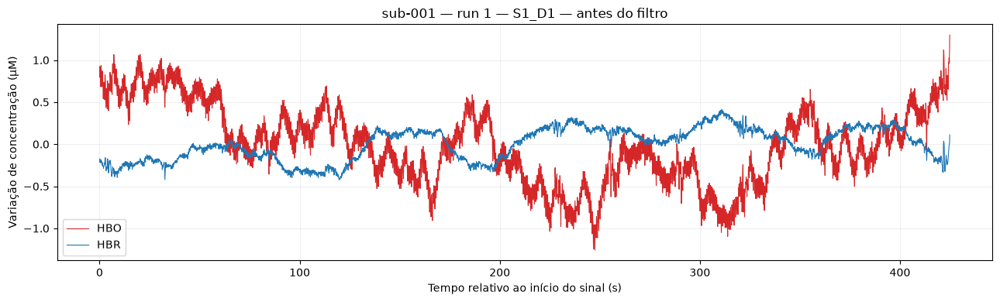

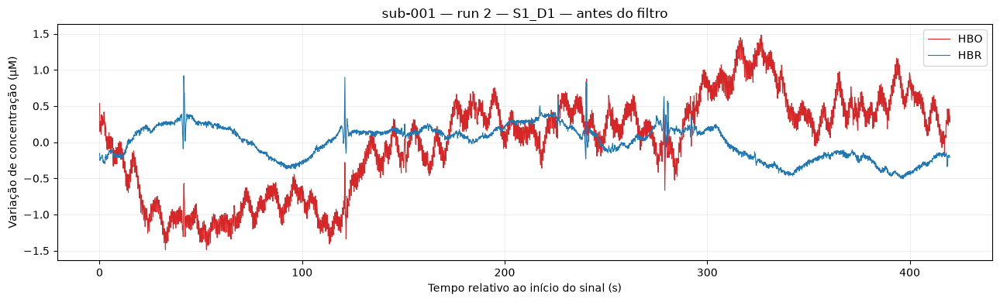

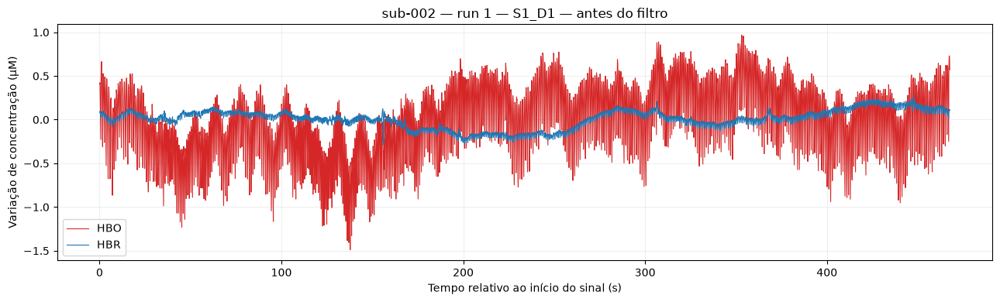

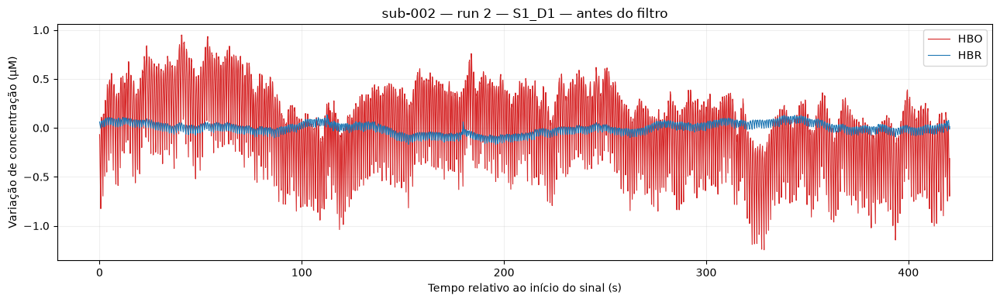


CONVERSÃO PARA HbO E HbR CONCLUÍDA
sujeito  run  n_HbO_total  n_HbR_total  n_HbO_nao_marcados  n_HbR_nao_marcados  n_pares_longos_validos  SSR_aplicada  valores_finitos
sub-001    1           28           28                  19                  19                      19         False             True
sub-001    2           28           28                  22                  22                      19         False             True
sub-002    1           28           28                  20                  20                      20         False             True
sub-002    2           28           28                  20                  20                      20         False             True

PPF utilizado: 6.0
Objetos disponíveis: piloto_haemo[(sujeito, run)].
Os objetos em densidade ótica foram preservados.
Os pares maus continuam presentes e marcados.
As contagens de séries não marcadas incluem canais curtos.
A seleção final dos canais longos ainda não foi efetuada.
Ainda não f

In [8]:
# ============================================================
# ETAPA 7 — CONVERSÃO PARA HbO E HbR
# ============================================================

PPF_PILOTO = 6.0

if set(piloto_od_pre_mbll) != set(piloto_runs):
    raise RuntimeError(
        "Faltam objetos de entrada para alguma run."
    )

if set(piloto_estado_ssr) != set(piloto_runs):
    raise RuntimeError(
        "Falta o registo da política SSR de alguma run."
    )

piloto_haemo = {}
piloto_tabelas_haemo = {}
registos_resumo_mbll = []


# ------------------------------------------------------------
# 7.1 Converter e verificar todas as runs
# ------------------------------------------------------------

for chave, raw_entrada in piloto_od_pre_mbll.items():
    print(
        f"\nA converter para HbO/HbR: "
        f"{chave[0]} — run {chave[1]}..."
    )

    if not all(
        tipo == "fnirs_od"
        for tipo in raw_entrada.get_channel_types()
    ):
        raise RuntimeError(
            f"A entrada não contém apenas densidade ótica: {chave}"
        )

    pares_antes = {
        nome.split()[0]
        for nome in raw_entrada.ch_names
    }

    pares_maus_antes = {
        nome.split()[0]
        for nome in raw_entrada.info["bads"]
    }

    raw_haemo_piloto = mne.preprocessing.nirs.beer_lambert_law(
        raw_entrada,
        ppf=PPF_PILOTO,
    )

    tipos_haemo = raw_haemo_piloto.get_channel_types()

    if not all(
        tipo in ("hbo", "hbr")
        for tipo in tipos_haemo
    ):
        raise RuntimeError(
            f"Tipos de canal inesperados após conversão: {chave}"
        )

    if (
        raw_haemo_piloto.n_times != raw_entrada.n_times
        or raw_haemo_piloto.info["sfreq"] != raw_entrada.info["sfreq"]
        or raw_haemo_piloto.first_samp != raw_entrada.first_samp
    ):
        raise RuntimeError(
            f"A grelha temporal mudou durante a conversão: {chave}"
        )

    anotacoes_preservadas = (
        np.array_equal(
            raw_haemo_piloto.annotations.onset,
            raw_entrada.annotations.onset,
        )
        and np.array_equal(
            raw_haemo_piloto.annotations.duration,
            raw_entrada.annotations.duration,
        )
        and np.array_equal(
            raw_haemo_piloto.annotations.description,
            raw_entrada.annotations.description,
        )
        and (
            raw_haemo_piloto.annotations.orig_time
            == raw_entrada.annotations.orig_time
        )
    )

    if not anotacoes_preservadas:
        raise RuntimeError(
            f"As anotações mudaram durante a conversão: {chave}"
        )

    if not np.isfinite(raw_haemo_piloto.get_data()).all():
        raise RuntimeError(
            f"Existem valores não finitos após conversão: {chave}"
        )

    tabela_haemo = pd.DataFrame({
        "canal": raw_haemo_piloto.ch_names,
        "par": [
            nome.split()[0]
            for nome in raw_haemo_piloto.ch_names
        ],
        "cromoforo": tipos_haemo,
        "marcado_mau": [
            nome in raw_haemo_piloto.info["bads"]
            for nome in raw_haemo_piloto.ch_names
        ],
    })

    geometria_pares = piloto_sci_pares[chave][
        ["par", "distancia_mm", "tipo_distancia"]
    ]

    tabela_haemo = tabela_haemo.merge(
        geometria_pares,
        on="par",
        how="left",
        validate="many_to_one",
        sort=False,
    )

    if tabela_haemo[
        ["distancia_mm", "tipo_distancia"]
    ].isna().any().any():
        raise RuntimeError(
            f"Existem canais sem correspondência geométrica: {chave}"
        )

    pares_depois = set(tabela_haemo["par"])

    pares_maus_depois = set(
        tabela_haemo.loc[
            tabela_haemo["marcado_mau"],
            "par",
        ]
    )

    if pares_depois != pares_antes:
        raise RuntimeError(
            f"A identidade dos pares mudou: {chave}"
        )

    if pares_maus_depois != pares_maus_antes:
        raise RuntimeError(
            f"A identidade dos pares maus mudou: {chave}"
        )

    for par, grupo in tabela_haemo.groupby("par", sort=False):
        if (
            len(grupo) != 2
            or set(grupo["cromoforo"]) != {"hbo", "hbr"}
        ):
            raise RuntimeError(
                f"O par {par} não tem exatamente HbO e HbR: {chave}"
            )

        if grupo["marcado_mau"].nunique() != 1:
            raise RuntimeError(
                f"Qualidade inconsistente entre HbO e HbR "
                f"no par {par}: {chave}"
            )

    piloto_haemo[chave] = raw_haemo_piloto
    piloto_tabelas_haemo[chave] = tabela_haemo

    validos = ~tabela_haemo["marcado_mau"]

    registos_resumo_mbll.append({
        "sujeito": chave[0],
        "run": chave[1],
        "n_HbO_total": int(
            (tabela_haemo["cromoforo"] == "hbo").sum()
        ),
        "n_HbR_total": int(
            (tabela_haemo["cromoforo"] == "hbr").sum()
        ),
        "n_HbO_nao_marcados": int(
            (
                (tabela_haemo["cromoforo"] == "hbo")
                & validos
            ).sum()
        ),
        "n_HbR_nao_marcados": int(
            (
                (tabela_haemo["cromoforo"] == "hbr")
                & validos
            ).sum()
        ),
        "n_pares_longos_validos": int(
            tabela_haemo.loc[
                validos
                & (tabela_haemo["tipo_distancia"] == "longo"),
                "par",
            ].nunique()
        ),
        "SSR_aplicada": piloto_estado_ssr[chave]["SSR_aplicada"],
        "valores_finitos": True,
    })


# ------------------------------------------------------------
# 7.2 Guardar os sinais, tabelas e parâmetros
# ------------------------------------------------------------

for chave, raw_haemo_piloto in piloto_haemo.items():
    objetos = piloto_runs[chave]
    id_gravacao = objetos["id_gravacao"]
    pasta_saida = Path(objetos["pasta_saida_prevista"])

    raw_haemo_piloto.save(
        pasta_saida / f"{id_gravacao}_haemo_unfiltered_raw.fif",
        overwrite=True,
        fmt="double",
        verbose=False,
    )

    piloto_tabelas_haemo[chave].to_csv(
        pasta_saida / f"{id_gravacao}_haemo_channels.csv",
        index=False,
        encoding="utf-8-sig",
    )

    parametros_mbll = {
        "id_gravacao": id_gravacao,
        "pipeline_version": VERSAO_PIPELINE_PILOTO,
        "etapa": 7,
        "mne_version": version("mne"),
        "metodo": "mne.preprocessing.nirs.beer_lambert_law",
        "ppf": PPF_PILOTO,
        "ppf_comum_aos_comprimentos_onda": True,
        "n_series": len(raw_haemo_piloto.ch_names),
        "n_amostras": int(raw_haemo_piloto.n_times),
        "sfreq_hz": float(raw_haemo_piloto.info["sfreq"]),
        "tddr_aplicado": True,
        "SSR_aplicada": piloto_estado_ssr[chave]["SSR_aplicada"],
        "motivo_SSR": piloto_estado_ssr[chave]["motivo"],
        "filtro_hemodinamico_aplicado": False,
        "selecao_final_canais_longos": False,
        "bads": list(raw_haemo_piloto.info["bads"]),
        "anotacoes_preservadas": True,
        "valores_finitos": True,
        "conversao_uM_apenas_na_figura": True,
    }

    (
        pasta_saida / f"{id_gravacao}_mbll_parameters.json"
    ).write_text(
        json.dumps(
            parametros_mbll,
            ensure_ascii=False,
            indent=2,
        ),
        encoding="utf-8",
    )

    # --------------------------------------------------------
    # 7.3 Inspeção do mesmo par utilizado na etapa TDDR
    # --------------------------------------------------------

    if par_visualizacao_tddr is not None:
        indices_par = [
            indice
            for indice, nome in enumerate(raw_haemo_piloto.ch_names)
            if nome.split()[0] == par_visualizacao_tddr
        ]

        fig_haemo, ax_haemo = plt.subplots(figsize=(13, 4))

        for indice in indices_par:
            cromoforo = (
                raw_haemo_piloto.get_channel_types()[indice]
            )

            ax_haemo.plot(
                raw_haemo_piloto.times,
                raw_haemo_piloto.get_data(picks=[indice])[0] * 1e6,
                color=(
                    "tab:red" if cromoforo == "hbo" else "tab:blue"
                ),
                linewidth=0.8,
                label=cromoforo.upper(),
            )

        ax_haemo.set(
            title=(
                f"{chave[0]} — run {chave[1]} — "
                f"{par_visualizacao_tddr} — antes do filtro"
            ),
            xlabel="Tempo relativo ao início do sinal (s)",
            ylabel="Variação de concentração (µM)",
        )

        ax_haemo.grid(alpha=0.2)
        ax_haemo.legend()
        fig_haemo.tight_layout()

        fig_haemo.savefig(
            pasta_saida / f"{id_gravacao}_haemo_unfiltered.png",
            dpi=300,
            bbox_inches="tight",
        )

        plt.show()


# ------------------------------------------------------------
# 7.4 Resumo
# ------------------------------------------------------------

df_mbll_piloto = pd.DataFrame(registos_resumo_mbll)

print("\n" + "=" * 70)
print("CONVERSÃO PARA HbO E HbR CONCLUÍDA")
print("=" * 70)

print(df_mbll_piloto.to_string(index=False))

print(f"\nPPF utilizado: {PPF_PILOTO}")
print("Objetos disponíveis: piloto_haemo[(sujeito, run)].")
print("Os objetos em densidade ótica foram preservados.")
print("Os pares maus continuam presentes e marcados.")
print("As contagens de séries não marcadas incluem canais curtos.")
print("A seleção final dos canais longos ainda não foi efetuada.")
print("Ainda não foi aplicado o filtro hemodinâmico.")
print("Não foram criadas épocas ou ajustados modelos.")
print("\nEtapa 7 concluída.")

## Etapa 8 — Filtragem temporal de HbO e HbR

### Objetivo
Aplicar o mesmo filtro hemodinâmico às quatro runs,
antes da seleção final dos canais longos e da criação de épocas.

### Parâmetros
- Limite inferior: 0,01 Hz.
- Limite superior: 0,50 Hz.
- Método: IIR Butterworth.
- Parâmetro de desenho: order = 4.
- Representação: secções de segunda ordem, SOS.
- Aplicação: fase zero, nos dois sentidos.

A ordem efetiva reportada pelo MNE inclui a transformação
passa-banda e a aplicação nos dois sentidos.

### Preservação
- piloto_haemo: sinal anterior à filtragem.
- piloto_haemo_filtrado: cópia após filtragem.

Filtrar explicitamente todas as séries HbO e HbR,
incluindo as que estão marcadas como más.

A filtragem não reclassifica canais maus como válidos.

### Verificações
- Frequências compatíveis com a amostragem.
- Valores finitos após filtragem.
- Canais e grelha temporal preservados.
- Anotações e marcações de qualidade preservadas.

### Visualização
Comparar antes e depois no mesmo par longo comum
utilizado nas etapas anteriores, separando HbO e HbR.

A figura é ilustrativa, não uma validação de todos os canais.

### Limitações
A filtragem não substitui o controlo da fisiologia superficial.

A fase zero pode espalhar alterações do sinal para instantes
anteriores e posteriores ao acontecimento.

Não interpretar a posição de uma alteração na curva filtrada
como prova de início instantâneo de uma resposta cerebral.

### Resultados guardados
Por participante e run:
- Sinal filtrado.
- Figura antes/depois.
- Parâmetros e histórico.

### Próxima etapa
Selecionar os canais longos que não estão marcados como maus.


A filtrar sub-001 — run 1: 0.01–0.5 Hz...

A filtrar sub-001 — run 2: 0.01–0.5 Hz...

A filtrar sub-002 — run 1: 0.01–0.5 Hz...

A filtrar sub-002 — run 2: 0.01–0.5 Hz...


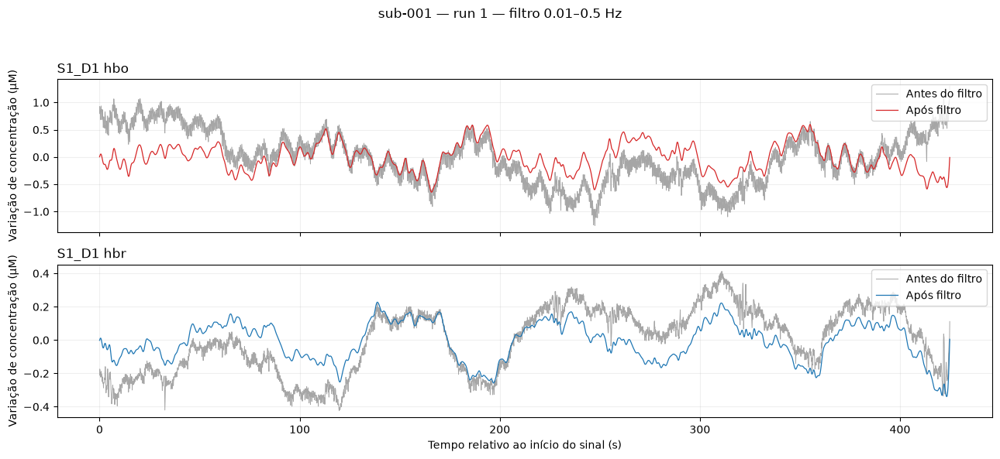

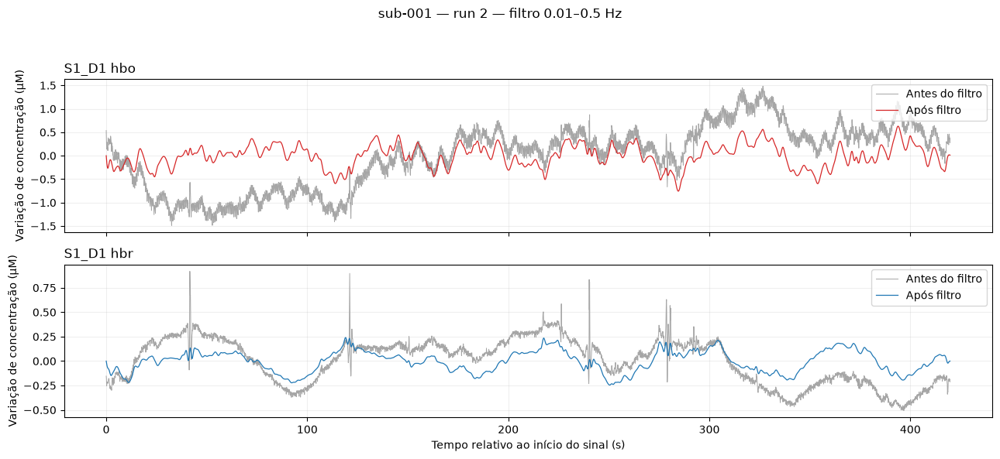

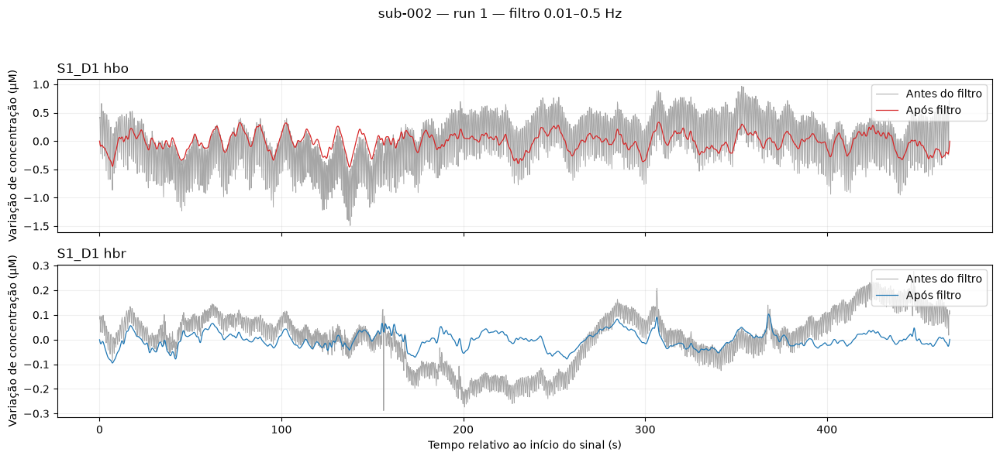

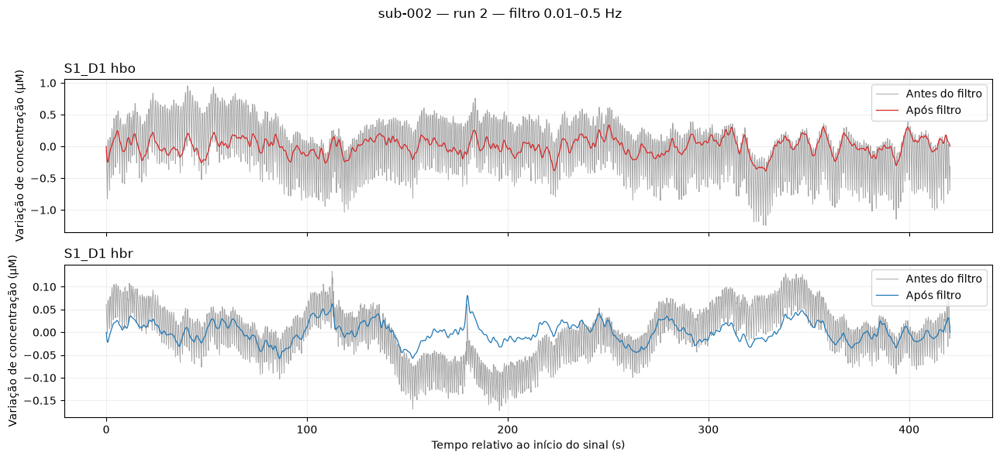


FILTRAGEM HEMODINÂMICA CONCLUÍDA
sujeito  run  n_series  n_series_nao_marcadas  n_amostras  highpass_info_hz  lowpass_info_hz  valores_finitos  bads_preservados  anotacoes_preservadas
sub-001    1        56                     38        4323            0.0100           0.5000             True              True                   True
sub-001    2        56                     44        4271            0.0100           0.5000             True              True                   True
sub-002    1        56                     40        4757            0.0100           0.5000             True              True                   True
sub-002    2        56                     40        4278            0.0100           0.5000             True              True                   True

Filtro: 0.01–0.5 Hz
Método: iir
Parâmetros IIR: {'order': 4, 'ftype': 'butter', 'output': 'sos'}
Fase: zero

Objetos disponíveis: piloto_haemo_filtrado[(sujeito, run)].
Os objetos anteriores em piloto_haemo for

In [9]:
# ============================================================
# ETAPA 8 — FILTRAGEM TEMPORAL DE HbO E HbR
# ============================================================

LOW_CUTOFF_HZ_PILOTO = 0.01
HIGH_CUTOFF_HZ_PILOTO = 0.50

METODO_FILTRO_PILOTO = "iir"
FASE_FILTRO_PILOTO = "zero"

IIR_PARAMS_PILOTO = {
    "order": 4,
    "ftype": "butter",
    "output": "sos",
}

SKIP_ANNOTATIONS_FILTRO_PILOTO = ("edge", "bad_acq_skip")

if set(piloto_haemo) != set(piloto_runs):
    raise RuntimeError(
        "Faltam objetos HbO/HbR para alguma run."
    )

# ------------------------------------------------------------
# 8.1 Verificar as entradas antes de filtrar
# ------------------------------------------------------------

for chave, raw_entrada in piloto_haemo.items():
    if not all(
        tipo in ("hbo", "hbr")
        for tipo in raw_entrada.get_channel_types()
    ):
        raise RuntimeError(
            f"A entrada deve conter apenas HbO e HbR: {chave}"
        )

    nyquist = float(raw_entrada.info["sfreq"]) / 2

    if not (
        0
        < LOW_CUTOFF_HZ_PILOTO
        < HIGH_CUTOFF_HZ_PILOTO
        < nyquist
    ):
        raise ValueError(
            f"Limites do filtro incompatíveis com a amostragem: {chave}"
        )

    if not np.isfinite(raw_entrada.get_data()).all():
        raise RuntimeError(
            f"Existem valores não finitos antes da filtragem: {chave}"
        )


# ------------------------------------------------------------
# 8.2 Filtrar cópias e verificar a integridade
# ------------------------------------------------------------

piloto_haemo_filtrado = {}
registos_resumo_filtro = []

for chave, raw_entrada in piloto_haemo.items():
    print(
        f"\nA filtrar {chave[0]} — run {chave[1]}: "
        f"{LOW_CUTOFF_HZ_PILOTO}–{HIGH_CUTOFF_HZ_PILOTO} Hz..."
    )

    raw_saida = raw_entrada.copy().filter(
        l_freq=LOW_CUTOFF_HZ_PILOTO,
        h_freq=HIGH_CUTOFF_HZ_PILOTO,
        picks=np.arange(len(raw_entrada.ch_names)),
        method=METODO_FILTRO_PILOTO,
        iir_params=IIR_PARAMS_PILOTO.copy(),
        phase=FASE_FILTRO_PILOTO,
        skip_by_annotation=SKIP_ANNOTATIONS_FILTRO_PILOTO,
        pad="reflect_limited",
        verbose=False,
    )

    if (
        raw_saida.ch_names != raw_entrada.ch_names
        or raw_saida.n_times != raw_entrada.n_times
        or raw_saida.first_samp != raw_entrada.first_samp
        or raw_saida.info["sfreq"] != raw_entrada.info["sfreq"]
    ):
        raise RuntimeError(
            f"Canais ou grelha temporal alterados: {chave}"
        )

    if raw_saida.info["bads"] != raw_entrada.info["bads"]:
        raise RuntimeError(
            f"A marcação dos canais maus mudou: {chave}"
        )

    anotacoes_preservadas = (
        np.array_equal(
            raw_saida.annotations.onset,
            raw_entrada.annotations.onset,
        )
        and np.array_equal(
            raw_saida.annotations.duration,
            raw_entrada.annotations.duration,
        )
        and np.array_equal(
            raw_saida.annotations.description,
            raw_entrada.annotations.description,
        )
        and (
            raw_saida.annotations.orig_time
            == raw_entrada.annotations.orig_time
        )
    )

    if not anotacoes_preservadas:
        raise RuntimeError(
            f"As anotações mudaram durante a filtragem: {chave}"
        )

    if not np.isfinite(raw_saida.get_data()).all():
        raise RuntimeError(
            f"Existem valores não finitos após filtragem: {chave}"
        )

    piloto_haemo_filtrado[chave] = raw_saida

    registos_resumo_filtro.append({
        "sujeito": chave[0],
        "run": chave[1],
        "n_series": len(raw_saida.ch_names),
        "n_series_nao_marcadas": (
            len(raw_saida.ch_names)
            - len(raw_saida.info["bads"])
        ),
        "n_amostras": int(raw_saida.n_times),
        "highpass_info_hz": float(raw_saida.info["highpass"]),
        "lowpass_info_hz": float(raw_saida.info["lowpass"]),
        "valores_finitos": True,
        "bads_preservados": True,
        "anotacoes_preservadas": True,
    })


# ------------------------------------------------------------
# 8.3 Guardar sinais, parâmetros e figuras
# ------------------------------------------------------------

for chave, raw_saida in piloto_haemo_filtrado.items():
    objetos = piloto_runs[chave]
    raw_entrada = piloto_haemo[chave]

    pasta_saida = Path(objetos["pasta_saida_prevista"])
    id_gravacao = objetos["id_gravacao"]

    raw_saida.save(
        pasta_saida / f"{id_gravacao}_haemo_filtered_raw.fif",
        overwrite=True,
        fmt="double",
        verbose=False,
    )

    parametros_filtro = {
        "id_gravacao": id_gravacao,
        "pipeline_version": VERSAO_PIPELINE_PILOTO,
        "etapa": 8,
        "mne_version": version("mne"),
        "l_freq_hz": LOW_CUTOFF_HZ_PILOTO,
        "h_freq_hz": HIGH_CUTOFF_HZ_PILOTO,
        "metodo": METODO_FILTRO_PILOTO,
        "phase": FASE_FILTRO_PILOTO,
        "iir_params": IIR_PARAMS_PILOTO.copy(),
        "skip_by_annotation": list(
            SKIP_ANNOTATIONS_FILTRO_PILOTO
        ),
        "pad": "reflect_limited",
        "canais_filtrados": "todas as series HbO e HbR",
        "n_series": len(raw_saida.ch_names),
        "n_amostras": int(raw_saida.n_times),
        "sfreq_hz": float(raw_saida.info["sfreq"]),
        "ppf": PPF_PILOTO,
        "tddr_aplicado": True,
        "SSR_aplicada": piloto_estado_ssr[chave]["SSR_aplicada"],
        "motivo_SSR": piloto_estado_ssr[chave]["motivo"],
        "bads": list(raw_saida.info["bads"]),
        "selecao_final_canais_longos": False,
        "par_visualizacao": par_visualizacao_tddr,
    }

    (
        pasta_saida / f"{id_gravacao}_filter_parameters.json"
    ).write_text(
        json.dumps(
            parametros_filtro,
            ensure_ascii=False,
            indent=2,
        ),
        encoding="utf-8",
    )

    if par_visualizacao_tddr is not None:
        fig_filtro, eixos_filtro = plt.subplots(
            2,
            1,
            figsize=(13, 6),
            sharex=True,
        )

        for ax, cromoforo in zip(
            eixos_filtro,
            ("hbo", "hbr"),
        ):
            nome_canal = (
                f"{par_visualizacao_tddr} {cromoforo}"
            )

            if nome_canal not in raw_saida.ch_names:
                raise RuntimeError(
                    f"Canal de visualização ausente: {nome_canal}"
                )

            antes = (
                raw_entrada.get_data(picks=[nome_canal])[0]
                * 1e6
            )

            depois = (
                raw_saida.get_data(picks=[nome_canal])[0]
                * 1e6
            )

            ax.plot(
                raw_entrada.times,
                antes,
                color="0.65",
                linewidth=0.7,
                label="Antes do filtro",
            )

            ax.plot(
                raw_saida.times,
                depois,
                color=(
                    "tab:red"
                    if cromoforo == "hbo"
                    else "tab:blue"
                ),
                linewidth=0.9,
                label="Após filtro",
            )

            ax.set_title(nome_canal, loc="left")
            ax.set_ylabel("Variação de concentração (µM)")
            ax.grid(alpha=0.2)
            ax.legend(loc="upper right")

        eixos_filtro[-1].set_xlabel(
            "Tempo relativo ao início do sinal (s)"
        )

        fig_filtro.suptitle(
            f"{chave[0]} — run {chave[1]} — "
            f"filtro {LOW_CUTOFF_HZ_PILOTO}–"
            f"{HIGH_CUTOFF_HZ_PILOTO} Hz"
        )

        fig_filtro.tight_layout(rect=(0, 0, 1, 0.94))

        fig_filtro.savefig(
            pasta_saida / f"{id_gravacao}_filter_comparison.png",
            dpi=300,
            bbox_inches="tight",
        )

        plt.show()


# ------------------------------------------------------------
# 8.4 Resumo
# ------------------------------------------------------------

df_filtro_piloto = pd.DataFrame(registos_resumo_filtro)

print("\n" + "=" * 70)
print("FILTRAGEM HEMODINÂMICA CONCLUÍDA")
print("=" * 70)

print(
    df_filtro_piloto.to_string(
        index=False,
        float_format=lambda valor: f"{valor:.4f}",
    )
)

print(
    f"\nFiltro: {LOW_CUTOFF_HZ_PILOTO}–"
    f"{HIGH_CUTOFF_HZ_PILOTO} Hz"
)
print(f"Método: {METODO_FILTRO_PILOTO}")
print(f"Parâmetros IIR: {IIR_PARAMS_PILOTO}")
print(f"Fase: {FASE_FILTRO_PILOTO}")

print(
    "\nObjetos disponíveis: "
    "piloto_haemo_filtrado[(sujeito, run)]."
)

print("Os objetos anteriores em piloto_haemo foram preservados.")
print("Todos os canais continuam presentes.")
print("Os canais maus continuam marcados.")
print("Não foi aplicada SSR nesta versão de referência.")
print("Não foram criadas épocas ou ajustados modelos.")
print("Resultados guardados nas pastas da versão piloto.")
print("\nEtapa 8 concluída.")

## Etapa 9 — Seleção dos canais longos válidos

### Objetivo
Criar os sinais que serão usados para extrair as épocas,
mantendo apenas os canais longos elegíveis.

### Critérios
- Canal HbO ou HbR.
- Não estar marcado como mau.
- Distância fonte–detetor superior a 15 mm.
- Sem limite máximo adicional nesta versão.

Cada par selecionado deve conter exatamente
uma série HbO e uma série HbR.

“Válido” significa que cumpre estes critérios;
não demonstra origem exclusivamente cortical.

### Preservação
- piloto_haemo_filtrado: todos os canais, preservados.
- piloto_longos: cópia apenas com os canais selecionados.

Não alterar os valores dos canais retidos,
a grelha temporal ou as anotações.

### Diferenças entre runs
A seleção é feita separadamente em cada run.

Não excluir automaticamente de uma run um canal
que foi rejeitado noutra.

Guardar a disponibilidade dos canais para decidir
posteriormente a análise entre participantes.

### Resultados guardados
Por participante e run:
- Sinal contínuo dos canais longos selecionados.
- Tabela de inclusão/exclusão de todos os canais.
- Tabela dos pares incluídos.
- Parâmetros.

### Nesta etapa
Não criar épocas.
Não combinar runs ou participantes.
Não aplicar novos filtros ou correções.

In [4]:
from pathlib import Path
from datetime import datetime
import json
import pandas as pd

PASTA_ESTUDO = Path(
    r"C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra"
    r"\PhD_Project_ARDITI_Guilherme Saldanha"
    r"\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI"
)

if not PASTA_ESTUDO.is_dir():
    raise NotADirectoryError(
        f"Pasta do estudo não encontrada:\n{PASTA_ESTUDO}"
    )

sufixo = "_haemo_filtered_raw.fif"
registos = []

for sujeito in ("sub-001", "sub-002"):
    pasta_sujeito = PASTA_ESTUDO / sujeito

    if not pasta_sujeito.is_dir():
        print(f"\nPasta não encontrada: {pasta_sujeito}")
        continue

    ficheiros = sorted(
        pasta_sujeito.rglob(f"*{sufixo}")
    )

    if not ficheiros:
        print(
            f"\nNão foram encontrados FIF filtrados em: "
            f"{pasta_sujeito}"
        )
        continue

    for ficheiro in ficheiros:
        id_gravacao = ficheiro.name[:-len(sufixo)]

        caminho_json = (
            ficheiro.parent
            / f"{id_gravacao}_filter_parameters.json"
        )

        parametros = {}
        estado_json = "ausente"

        if caminho_json.is_file():
            try:
                parametros = json.loads(
                    caminho_json.read_text(encoding="utf-8-sig")
                )
                estado_json = "lido"
            except (OSError, ValueError) as erro:
                estado_json = f"erro: {erro}"

        registos.append({
            "sujeito": sujeito,
            "id_gravacao": id_gravacao,
            "pipeline_version": parametros.get(
                "pipeline_version", "não disponível"
            ),
            "n_amostras": parametros.get("n_amostras"),
            "l_freq_hz": parametros.get("l_freq_hz"),
            "h_freq_hz": parametros.get("h_freq_hz"),
            "SSR_aplicada": parametros.get("SSR_aplicada"),
            "JSON": estado_json,
            "modificacao_local": datetime.fromtimestamp(
                ficheiro.stat().st_mtime
            ).strftime("%Y-%m-%d %H:%M:%S"),
            "caminho": str(ficheiro),
        })

df_localizacao_piloto = pd.DataFrame(registos)

print("\n" + "=" * 70)
print("LOCALIZAÇÃO DOS RESULTADOS FILTRADOS")
print("=" * 70)

for numero, registo in enumerate(registos, start=1):
    print(f"\n[{numero}] {registo['id_gravacao']}")
    print("Versão:", registo["pipeline_version"])
    print("Amostras:", registo["n_amostras"])
    print(
        "Filtro:",
        registo["l_freq_hz"],
        "–",
        registo["h_freq_hz"],
        "Hz",
    )
    print("SSR aplicada:", registo["SSR_aplicada"])
    print("JSON:", registo["JSON"])
    print("Modificação local:", registo["modificacao_local"])
    print("Caminho:", registo["caminho"])

print(f"\nTotal de FIF encontrados: {len(registos)}")
print("Não foram carregados sinais nem alterados ficheiros.")


LOCALIZAÇÃO DOS RESULTADOS FILTRADOS

[1] sub-001_ses-01_tk-dm_run-1_nirs_001
Versão: pilot_dm_epochs_v01
Amostras: 4323
Filtro: 0.01 – 0.5 Hz
SSR aplicada: False
JSON: lido
Modificação local: 2026-11-17 15:52:01
Caminho: C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\fNIRS_epochs_derivatives\pilot_dm_epochs_v01\sub-001_ses-01_tk-dm_run-1_nirs_001\sub-001_ses-01_tk-dm_run-1_nirs_001_haemo_filtered_raw.fif

[2] sub-001_ses-01_tk-dm_run-2_nirs_001
Versão: pilot_dm_epochs_v01
Amostras: 4271
Filtro: 0.01 – 0.5 Hz
SSR aplicada: False
JSON: lido
Modificação local: 2026-11-17 15:52:03
Caminho: C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\fNIRS_epochs_derivatives\pilot_dm_epochs_v01\sub-001_ses-01_tk-dm_run-2_nirs_001\sub-001_ses-01_tk-dm_run-2_nirs_001_h

In [6]:
# ============================================================
# RECUPERAR A SESSÃO ATÉ AO FINAL DA ETAPA 8
#
# Versão: pilot_dm_epochs_v01
# Participantes: sub-001 e sub-002
# Runs: 1 e 2
#
# Não aplica novamente TDDR, MBLL ou filtragem.
# Não grava nem substitui ficheiros.
# ============================================================

from pathlib import Path
from importlib.metadata import version
import json

import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Configuração e caminhos exatos
# ------------------------------------------------------------

PASTA_ESTUDO = Path(
    r"C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra"
    r"\PhD_Project_ARDITI_Guilherme Saldanha"
    r"\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI"
)

VERSAO_RECUPERAR = "pilot_dm_epochs_v01"

GRAVACOES_RECUPERAR = {
    ("sub-001", 1): {
        "id_gravacao": "sub-001_ses-01_tk-dm_run-1_nirs_001",
        "n_amostras": 4323,
        "n_series_nao_marcadas": 38,
    },
    ("sub-001", 2): {
        "id_gravacao": "sub-001_ses-01_tk-dm_run-2_nirs_001",
        "n_amostras": 4271,
        "n_series_nao_marcadas": 44,
    },
    ("sub-002", 1): {
        "id_gravacao": "sub-002_ses-01_tk-dm_run-1_nirs_002",
        "n_amostras": 4757,
        "n_series_nao_marcadas": 40,
    },
    ("sub-002", 2): {
        "id_gravacao": "sub-002_ses-01_tk-dm_run-2_nirs_002",
        "n_amostras": 4278,
        "n_series_nao_marcadas": 40,
    },
}

if not PASTA_ESTUDO.is_dir():
    raise NotADirectoryError(
        f"Pasta do estudo não encontrada:\n{PASTA_ESTUDO}"
    )

caminhos_recuperacao = {}
ficheiros_em_falta = []

for chave, esperado in GRAVACOES_RECUPERAR.items():
    sujeito, run = chave
    id_gravacao = esperado["id_gravacao"]

    pasta_saida = (
        PASTA_ESTUDO
        / sujeito
        / "fNIRS_epochs_derivatives"
        / VERSAO_RECUPERAR
        / id_gravacao
    )

    caminho_fif = (
        pasta_saida
        / f"{id_gravacao}_haemo_filtered_raw.fif"
    )

    caminho_json = (
        pasta_saida
        / f"{id_gravacao}_filter_parameters.json"
    )

    caminhos_recuperacao[chave] = {
        "pasta_saida": pasta_saida,
        "fif": caminho_fif,
        "json": caminho_json,
    }

    for caminho in (caminho_fif, caminho_json):
        if not caminho.is_file():
            ficheiros_em_falta.append(str(caminho))

if ficheiros_em_falta:
    raise FileNotFoundError(
        "Faltam os seguintes ficheiros:\n"
        + "\n".join(ficheiros_em_falta)
    )

print("Os quatro FIF e os quatro JSON foram localizados.")


# ------------------------------------------------------------
# 2. Ler e verificar os parâmetros da Etapa 8
# ------------------------------------------------------------

parametros_recuperados = {}

campos_obrigatorios = [
    "id_gravacao",
    "pipeline_version",
    "l_freq_hz",
    "h_freq_hz",
    "metodo",
    "phase",
    "iir_params",
    "ppf",
    "tddr_aplicado",
    "SSR_aplicada",
    "motivo_SSR",
    "bads",
    "n_series",
    "n_amostras",
    "sfreq_hz",
]

for chave, caminhos in caminhos_recuperacao.items():
    parametros = json.loads(
        caminhos["json"].read_text(encoding="utf-8-sig")
    )

    em_falta = [
        campo
        for campo in campos_obrigatorios
        if campo not in parametros
    ]

    if em_falta:
        raise RuntimeError(
            f"JSON incompleto para {chave}: {em_falta}"
        )

    esperado = GRAVACOES_RECUPERAR[chave]

    if parametros["id_gravacao"] != esperado["id_gravacao"]:
        raise RuntimeError(
            f"O identificador do JSON não corresponde à gravação: {chave}"
        )

    if parametros["pipeline_version"] != VERSAO_RECUPERAR:
        raise RuntimeError(
            f"Versão de pipeline inesperada: {chave}"
        )

    parametros_corretos = (
        np.isclose(float(parametros["l_freq_hz"]), 0.01)
        and np.isclose(float(parametros["h_freq_hz"]), 0.50)
        and parametros["metodo"] == "iir"
        and parametros["phase"] == "zero"
        and parametros["iir_params"] == {
            "order": 4,
            "ftype": "butter",
            "output": "sos",
        }
        and np.isclose(float(parametros["ppf"]), 6.0)
        and parametros["tddr_aplicado"] is True
        and parametros["SSR_aplicada"] is False
    )

    if not parametros_corretos:
        raise RuntimeError(
            f"Os parâmetros não correspondem à versão "
            f"de referência do piloto: {chave}"
        )

    if (
        int(parametros["n_amostras"]) != esperado["n_amostras"]
        or int(parametros["n_series"]) != 56
    ):
        raise RuntimeError(
            f"As dimensões registadas não correspondem "
            f"à execução apresentada: {chave}"
        )

    parametros_recuperados[chave] = parametros

print("Os parâmetros das quatro runs foram verificados.")


# ------------------------------------------------------------
# 3. Carregar os sinais filtrados
# ------------------------------------------------------------

haemo_filtrado_recuperado = {}
runs_recuperadas = {}
estado_ssr_recuperado = {}
registos_recuperacao = []

for chave, caminhos in caminhos_recuperacao.items():
    sujeito, run = chave
    parametros = parametros_recuperados[chave]
    esperado = GRAVACOES_RECUPERAR[chave]

    print(f"\nA carregar {sujeito} — run {run}...")

    raw = mne.io.read_raw_fif(
        caminhos["fif"],
        preload=True,
        verbose=False,
    )

    tipos = raw.get_channel_types()

    if not all(tipo in ("hbo", "hbr") for tipo in tipos):
        raise RuntimeError(
            f"O sinal contém canais diferentes de HbO/HbR: {chave}"
        )

    if (
        len(raw.ch_names) != int(parametros["n_series"])
        or raw.n_times != int(parametros["n_amostras"])
        or not np.isclose(
            float(raw.info["sfreq"]),
            float(parametros["sfreq_hz"]),
        )
    ):
        raise RuntimeError(
            f"As dimensões do FIF diferem do JSON: {chave}"
        )

    if set(raw.info["bads"]) != set(parametros["bads"]):
        raise RuntimeError(
            f"A marcação dos canais maus difere do JSON: {chave}"
        )

    n_nao_marcadas = (
        len(raw.ch_names) - len(raw.info["bads"])
    )

    if n_nao_marcadas != esperado["n_series_nao_marcadas"]:
        raise RuntimeError(
            f"Número inesperado de séries não marcadas: {chave}"
        )

    if (
        not np.isclose(float(raw.info["highpass"]), 0.01)
        or not np.isclose(float(raw.info["lowpass"]), 0.50)
    ):
        raise RuntimeError(
            f"Os metadados do filtro diferem do esperado: {chave}"
        )

    if not np.isfinite(raw.get_data()).all():
        raise RuntimeError(
            f"Existem valores não finitos no sinal: {chave}"
        )

    pares = {}

    for nome, tipo in zip(raw.ch_names, tipos):
        par = nome.split()[0]
        pares.setdefault(par, []).append((nome, tipo))

    for par, series in pares.items():
        if (
            len(series) != 2
            or {tipo for _, tipo in series} != {"hbo", "hbr"}
        ):
            raise RuntimeError(
                f"Par sem HbO/HbR completos: {par}, {chave}"
            )

        estados_maus = {
            nome in raw.info["bads"]
            for nome, _ in series
        }

        if len(estados_maus) != 1:
            raise RuntimeError(
                f"Marcação de qualidade inconsistente "
                f"entre HbO e HbR: {par}, {chave}"
            )

    haemo_filtrado_recuperado[chave] = raw

    runs_recuperadas[chave] = {
        "id_gravacao": esperado["id_gravacao"],
        "pasta_saida_prevista": caminhos["pasta_saida"],
        "ficheiro_filtrado_recuperado": caminhos["fif"],
    }

    estado_ssr_recuperado[chave] = {
        "SSR_aplicada": parametros["SSR_aplicada"],
        "motivo": parametros["motivo_SSR"],
    }

    registos_recuperacao.append({
        "sujeito": sujeito,
        "run": run,
        "n_HbO": tipos.count("hbo"),
        "n_HbR": tipos.count("hbr"),
        "n_series_nao_marcadas": n_nao_marcadas,
        "n_amostras": int(raw.n_times),
        "n_anotacoes": len(raw.annotations),
        "SSR_aplicada": parametros["SSR_aplicada"],
        "valores_finitos": True,
    })


# ------------------------------------------------------------
# 4. Confirmar o limiar dos canais longos
# ------------------------------------------------------------

print(
    "\nOs sinais já foram carregados e verificados.\n"
    "Falta confirmar o limiar para a seleção da Etapa 9."
)

texto_limiar = input(
    "\nIntroduz o limiar mínimo dos canais longos, em mm, "
    "conforme a configuração original.\n"
    "Se confirmaste que era 15 mm, escreve 15 e carrega Enter: "
).strip().replace(",", ".")

try:
    limiar_mm = float(texto_limiar)
except ValueError:
    raise ValueError(
        "O limiar deve ser um número em milímetros, "
        "confirmado na configuração original."
    ) from None

if not np.isfinite(limiar_mm) or limiar_mm <= 0:
    raise ValueError(
        "O limiar deve ser um número positivo e finito."
    )


# ------------------------------------------------------------
# 5. Reconstruir as variáveis necessárias à Etapa 9
# ------------------------------------------------------------

piloto_haemo_filtrado = haemo_filtrado_recuperado
piloto_runs = runs_recuperadas
piloto_estado_ssr = estado_ssr_recuperado

VERSAO_PIPELINE_PILOTO = VERSAO_RECUPERAR

parametros_referencia = parametros_recuperados[
    ("sub-001", 1)
]

PPF_PILOTO = float(parametros_referencia["ppf"])

LOW_CUTOFF_HZ_PILOTO = float(
    parametros_referencia["l_freq_hz"]
)

HIGH_CUTOFF_HZ_PILOTO = float(
    parametros_referencia["h_freq_hz"]
)

METODO_FILTRO_PILOTO = parametros_referencia["metodo"]
FASE_FILTRO_PILOTO = parametros_referencia["phase"]

IIR_PARAMS_PILOTO = dict(
    parametros_referencia["iir_params"]
)

SKIP_ANNOTATIONS_FILTRO_PILOTO = tuple(
    parametros_referencia.get(
        "skip_by_annotation",
        ("edge", "bad_acq_skip"),
    )
)

DISTANCIA_MIN_LONGA_M_PILOTO = limiar_mm / 1000
DISTANCIA_MAX_LONGA_M_PILOTO = None

df_recuperacao_piloto = pd.DataFrame(
    registos_recuperacao
)


# ------------------------------------------------------------
# 6. Resumo da recuperação
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SESSÃO RECUPERADA ATÉ AO FINAL DA ETAPA 8")
print("=" * 70)

print(df_recuperacao_piloto.to_string(index=False))

print(
    "\nVersão da pipeline:",
    VERSAO_PIPELINE_PILOTO,
)

print("Versão atual do MNE:", version("mne"))

print(
    "Versões do MNE registadas nos JSON:",
    sorted({
        p.get("mne_version", "não registada")
        for p in parametros_recuperados.values()
    }),
)

print(
    "Limiar mínimo confirmado para canais longos:",
    limiar_mm,
    "mm",
)

print("\nObjetos disponíveis:")
print("piloto_haemo_filtrado[(sujeito, run)]")
print("piloto_runs[(sujeito, run)]")
print("piloto_estado_ssr[(sujeito, run)]")

print("\nAs anotações foram carregadas dos FIF.")
print("A marcação dos canais maus foi conferida com os JSON.")
print("Não foi repetido qualquer processamento dos sinais.")
print("Não foram gravados ou substituídos ficheiros.")
print("As runs continuam separadas.")

print(
    "\nEsta recuperação disponibiliza as variáveis necessárias "
    "à Etapa 9; não reconstitui todos os objetos das etapas anteriores."
)

print("\nPodes agora executar a célula Python da Etapa 9.")

Os quatro FIF e os quatro JSON foram localizados.
Os parâmetros das quatro runs foram verificados.

A carregar sub-001 — run 1...

A carregar sub-001 — run 2...

A carregar sub-002 — run 1...

A carregar sub-002 — run 2...

Os sinais já foram carregados e verificados.
Falta confirmar o limiar para a seleção da Etapa 9.

SESSÃO RECUPERADA ATÉ AO FINAL DA ETAPA 8
sujeito  run  n_HbO  n_HbR  n_series_nao_marcadas  n_amostras  n_anotacoes  SSR_aplicada  valores_finitos
sub-001    1     28     28                     38        4323           42         False             True
sub-001    2     28     28                     44        4271           42         False             True
sub-002    1     28     28                     40        4757           42         False             True
sub-002    2     28     28                     40        4278           42         False             True

Versão da pipeline: pilot_dm_epochs_v01
Versão atual do MNE: 1.12.1
Versões do MNE registadas nos JSON: [

In [7]:
# ============================================================
# ETAPA 9 — SELEÇÃO DOS CANAIS LONGOS VÁLIDOS
# ============================================================

DISTANCIA_MAX_LONGA_M_PILOTO = None

if set(piloto_haemo_filtrado) != set(piloto_runs):
    raise RuntimeError(
        "Faltam sinais filtrados para alguma run."
    )

if (
    DISTANCIA_MAX_LONGA_M_PILOTO is not None
    and DISTANCIA_MAX_LONGA_M_PILOTO <= DISTANCIA_MIN_LONGA_M_PILOTO
):
    raise ValueError(
        "A distância máxima deve ser superior à mínima."
    )

piloto_longos = {}
piloto_selecao_longos = {}
piloto_pares_longos = {}

registos_resumo_longos = []


# ------------------------------------------------------------
# 9.1 Selecionar e verificar as quatro runs
# ------------------------------------------------------------

for chave, raw_entrada in piloto_haemo_filtrado.items():
    tipos = raw_entrada.get_channel_types()

    if not all(tipo in ("hbo", "hbr") for tipo in tipos):
        raise RuntimeError(
            f"A entrada deve conter apenas HbO e HbR: {chave}"
        )

    distancias_m = (
        mne.preprocessing.nirs.source_detector_distances(
            raw_entrada.info,
            picks=np.arange(len(raw_entrada.ch_names)),
        )
    )

    if (
        not np.isfinite(distancias_m).all()
        or np.any(distancias_m <= 0)
    ):
        raise RuntimeError(
            f"Existem distâncias inválidas: {chave}"
        )

    selecao = pd.DataFrame({
        "canal": raw_entrada.ch_names,
        "par": [
            nome.split()[0]
            for nome in raw_entrada.ch_names
        ],
        "cromoforo": tipos,
        "distancia_mm": distancias_m * 1000,
        "marcado_mau": [
            nome in raw_entrada.info["bads"]
            for nome in raw_entrada.ch_names
        ],
    })

    selecao["acima_distancia_minima"] = (
        distancias_m > DISTANCIA_MIN_LONGA_M_PILOTO
    )

    if DISTANCIA_MAX_LONGA_M_PILOTO is None:
        selecao["dentro_distancia_maxima"] = True
    else:
        selecao["dentro_distancia_maxima"] = (
            distancias_m <= DISTANCIA_MAX_LONGA_M_PILOTO
        )

    selecao["incluido"] = (
        ~selecao["marcado_mau"]
        & selecao["acima_distancia_minima"]
        & selecao["dentro_distancia_maxima"]
    )

    motivos = []

    for linha in selecao.itertuples(index=False):
        motivos_linha = []

        if linha.marcado_mau:
            motivos_linha.append("marcado como mau")

        if not linha.acima_distancia_minima:
            motivos_linha.append("distancia <= minimo")

        if not linha.dentro_distancia_maxima:
            motivos_linha.append("distancia > maximo")

        motivos.append(
            "; ".join(motivos_linha)
            if motivos_linha else "incluido"
        )

    selecao["motivo"] = motivos

    incluidos = selecao.loc[selecao["incluido"]].copy()

    if incluidos.empty:
        raise RuntimeError(
            f"Nenhum canal cumpre os critérios: {chave}"
        )

    for par, grupo in incluidos.groupby("par", sort=False):
        if (
            len(grupo) != 2
            or set(grupo["cromoforo"]) != {"hbo", "hbr"}
        ):
            raise RuntimeError(
                f"Par incompleto após seleção: {par}, {chave}"
            )

    canais_incluidos = incluidos["canal"].tolist()

    raw_selecionado = raw_entrada.copy().pick(
        canais_incluidos
    )

    if raw_selecionado.info["bads"]:
        raise RuntimeError(
            f"O objeto selecionado contém canais maus: {chave}"
        )

    if (
        raw_selecionado.n_times != raw_entrada.n_times
        or raw_selecionado.first_samp != raw_entrada.first_samp
        or raw_selecionado.info["sfreq"] != raw_entrada.info["sfreq"]
    ):
        raise RuntimeError(
            f"A grelha temporal mudou durante a seleção: {chave}"
        )

    if not np.array_equal(
        raw_selecionado.get_data(),
        raw_entrada.get_data(picks=canais_incluidos),
    ):
        raise RuntimeError(
            f"Os valores dos canais retidos mudaram: {chave}"
        )

    if not np.isfinite(raw_selecionado.get_data()).all():
        raise RuntimeError(
            f"Existem valores não finitos: {chave}"
        )

    anotacoes_preservadas = (
        np.array_equal(
            raw_selecionado.annotations.onset,
            raw_entrada.annotations.onset,
        )
        and np.array_equal(
            raw_selecionado.annotations.duration,
            raw_entrada.annotations.duration,
        )
        and np.array_equal(
            raw_selecionado.annotations.description,
            raw_entrada.annotations.description,
        )
        and (
            raw_selecionado.annotations.orig_time
            == raw_entrada.annotations.orig_time
        )
    )

    if not anotacoes_preservadas:
        raise RuntimeError(
            f"As anotações mudaram durante a seleção: {chave}"
        )

    pares_incluidos = (
        incluidos
        .groupby("par", sort=False)
        .agg(
            distancia_mm=("distancia_mm", "first"),
            n_cromoforos=("cromoforo", "nunique"),
        )
        .reset_index()
    )

    piloto_longos[chave] = raw_selecionado
    piloto_selecao_longos[chave] = selecao
    piloto_pares_longos[chave] = pares_incluidos

    registos_resumo_longos.append({
        "sujeito": chave[0],
        "run": chave[1],
        "n_pares": len(pares_incluidos),
        "n_HbO": int(
            (incluidos["cromoforo"] == "hbo").sum()
        ),
        "n_HbR": int(
            (incluidos["cromoforo"] == "hbr").sum()
        ),
        "n_series_total": len(raw_selecionado.ch_names),
        "n_amostras": int(raw_selecionado.n_times),
        "valores_preservados": True,
        "anotacoes_preservadas": True,
    })


# ------------------------------------------------------------
# 9.2 Guardar os resultados
# ------------------------------------------------------------

for chave, raw_selecionado in piloto_longos.items():
    objetos = piloto_runs[chave]
    id_gravacao = objetos["id_gravacao"]
    pasta_saida = Path(objetos["pasta_saida_prevista"])

    raw_selecionado.save(
        pasta_saida / f"{id_gravacao}_long_haemo_raw.fif",
        overwrite=True,
        fmt="double",
        verbose=False,
    )

    piloto_selecao_longos[chave].to_csv(
        pasta_saida / f"{id_gravacao}_long_channel_selection.csv",
        index=False,
        encoding="utf-8-sig",
    )

    piloto_pares_longos[chave].to_csv(
        pasta_saida / f"{id_gravacao}_long_pairs.csv",
        index=False,
        encoding="utf-8-sig",
    )

    parametros_longos = {
        "id_gravacao": id_gravacao,
        "pipeline_version": VERSAO_PIPELINE_PILOTO,
        "etapa": 9,
        "mne_version": version("mne"),
        "distancia_minima_m": DISTANCIA_MIN_LONGA_M_PILOTO,
        "criterio_minimo": "estritamente superior",
        "distancia_maxima_m": DISTANCIA_MAX_LONGA_M_PILOTO,
        "excluir_canais_marcados_maus": True,
        "canais_incluidos": list(raw_selecionado.ch_names),
        "n_pares": len(piloto_pares_longos[chave]),
        "n_amostras": int(raw_selecionado.n_times),
        "ppf": PPF_PILOTO,
        "tddr_aplicado": True,
        "SSR_aplicada": piloto_estado_ssr[chave]["SSR_aplicada"],
        "motivo_SSR": piloto_estado_ssr[chave]["motivo"],
        "filtro": {
            "l_freq_hz": LOW_CUTOFF_HZ_PILOTO,
            "h_freq_hz": HIGH_CUTOFF_HZ_PILOTO,
            "metodo": METODO_FILTRO_PILOTO,
            "fase": FASE_FILTRO_PILOTO,
            "iir_params": IIR_PARAMS_PILOTO.copy(),
        },
        "anotacoes_preservadas": True,
        "runs_combinadas": False,
    }

    (
        pasta_saida / f"{id_gravacao}_long_channel_parameters.json"
    ).write_text(
        json.dumps(
            parametros_longos,
            ensure_ascii=False,
            indent=2,
        ),
        encoding="utf-8",
    )


# ------------------------------------------------------------
# 9.3 Resumo e disponibilidade dos pares
# ------------------------------------------------------------

df_longos_piloto = pd.DataFrame(registos_resumo_longos)

print("=" * 70)
print("CANAIS LONGOS SELECIONADOS")
print("=" * 70)

print(df_longos_piloto.to_string(index=False))

todos_os_pares = sorted(
    set().union(*[
        set(tabela["par"])
        for tabela in piloto_pares_longos.values()
    ])
)

df_disponibilidade_pares_piloto = pd.DataFrame({
    f"{chave[0]}_run-{chave[1]}": [
        par in set(tabela["par"])
        for par in todos_os_pares
    ]
    for chave, tabela in piloto_pares_longos.items()
}, index=todos_os_pares)

df_disponibilidade_pares_piloto.index.name = "par"

print("\nDisponibilidade dos pares:")
print(df_disponibilidade_pares_piloto.to_string())

print("\nObjetos disponíveis: piloto_longos[(sujeito, run)].")
print("Os objetos completos filtrados foram preservados.")
print("Não foram impostos canais comuns às quatro runs.")
print("Não foram criadas épocas ou combinados participantes.")
print("Resultados guardados nas pastas da versão piloto.")
print("\nEtapa 9 concluída.")

CANAIS LONGOS SELECIONADOS
sujeito  run  n_pares  n_HbO  n_HbR  n_series_total  n_amostras  valores_preservados  anotacoes_preservadas
sub-001    1       19     19     19              38        4323                 True                   True
sub-001    2       19     19     19              38        4271                 True                   True
sub-002    1       20     20     20              40        4757                 True                   True
sub-002    2       20     20     20              40        4278                 True                   True

Disponibilidade dos pares:
       sub-001_run-1  sub-001_run-2  sub-002_run-1  sub-002_run-2
par                                                              
S1_D1           True           True           True           True
S1_D2           True           True           True           True
S2_D1           True           True           True           True
S2_D3           True           True           True           True
S3_D2    

## Etapa 10 — Inspeção das anotações antes da criação de épocas

### Objetivo
Confirmar os marcadores disponíveis nas quatro runs:
- Início do vídeo.
- Início do ecrã de decisão/resposta explícita.
- Resposta do participante, se registada.
- Outros marcadores ou anotações de qualidade.

### Procedimento
Listar todas as anotações e resumir as descrições por run.

Apresentar os tempos relativamente ao início do sinal,
preservando também os onsets originais do MNE.

Não atribuir significado experimental a códigos numéricos
sem confirmar o respetivo mapeamento.

### Nesta etapa
Não alterar os sinais ou as anotações.
Não criar épocas.
Não aplicar baseline.
Não combinar runs.
Não ajustar modelos.

In [8]:
# ============================================================
# ETAPA 10 — INSPEÇÃO DAS ANOTAÇÕES
# ============================================================

import numpy as np
import pandas as pd

if "piloto_longos" not in globals():
    raise RuntimeError(
        "O objeto piloto_longos não existe. "
        "Executar primeiro a recuperação e a Etapa 9."
    )

if set(piloto_longos) != set(piloto_runs):
    raise RuntimeError(
        "As runs de piloto_longos não correspondem a piloto_runs."
    )

piloto_tabelas_anotacoes = {}
resumos_anotacoes = []

for chave in sorted(piloto_longos):
    sujeito, run = chave
    raw = piloto_longos[chave]
    anotacoes = raw.annotations

    # Em anotações associadas a Raw, subtrair first_time
    # para apresentar tempos relativos ao início do sinal.
    onsets_relativos = (
        np.asarray(anotacoes.onset, dtype=float)
        - float(raw.first_time)
    )

    tabela = pd.DataFrame({
        "ordem": np.arange(1, len(anotacoes) + 1),
        "descricao": anotacoes.description,
        "onset_mne_s": anotacoes.onset,
        "onset_relativo_s": onsets_relativos,
        "duracao_s": anotacoes.duration,
    })

    tabela["fim_relativo_s"] = (
        tabela["onset_relativo_s"]
        + tabela["duracao_s"]
    )

    tabela["intervalo_desde_anterior_s"] = (
        tabela["onset_relativo_s"].diff()
    )

    piloto_tabelas_anotacoes[chave] = tabela

    resumo = (
        tabela.groupby("descricao", sort=False)
        .agg(
            n=("ordem", "size"),
            duracao_min_s=("duracao_s", "min"),
            duracao_max_s=("duracao_s", "max"),
            primeiro_onset_s=("onset_relativo_s", "min"),
            ultimo_onset_s=("onset_relativo_s", "max"),
        )
        .reset_index()
    )

    resumo.insert(0, "run", run)
    resumo.insert(0, "sujeito", sujeito)
    resumos_anotacoes.append(resumo)

    print("\n" + "=" * 90)
    print(f"{sujeito} — run {run}")
    print("=" * 90)

    print(
        f"Amostragem: {raw.info['sfreq']:.6f} Hz | "
        f"Amostras: {raw.n_times} | "
        f"Última amostra: {raw.times[-1]:.3f} s"
    )

    print(
        f"first_samp: {raw.first_samp} | "
        f"first_time: {raw.first_time:.6f} s"
    )

    print(
        "orig_time das anotações:",
        anotacoes.orig_time,
    )

    print("\nResumo por descrição:")
    print(
        resumo.to_string(
            index=False,
            float_format=lambda valor: f"{valor:.3f}",
        )
    )

    print("\nSequência completa das anotações:")
    print(
        tabela.to_string(
            index=False,
            float_format=lambda valor: f"{valor:.3f}",
        )
    )

df_resumo_anotacoes_piloto = pd.concat(
    resumos_anotacoes,
    ignore_index=True,
)

print("\n" + "=" * 90)
print("INSPEÇÃO DAS ANOTAÇÕES CONCLUÍDA")
print("=" * 90)

print(
    "Tabelas disponíveis: "
    "piloto_tabelas_anotacoes[(sujeito, run)]."
)

print("Resumo disponível: df_resumo_anotacoes_piloto.")
print("Não foram alterados sinais ou anotações.")
print("Não foram gravados ficheiros.")
print("Não foram criadas épocas nem aplicada baseline.")
print("\nEtapa 10 concluída.")


sub-001 — run 1
Amostragem: 10.172526 Hz | Amostras: 4323 | Última amostra: 424.870 s
first_samp: 0 | first_time: 0.000000 s
orig_time das anotações: 2026-08-04 14:08:30+00:00

Resumo por descrição:
sujeito  run descricao  n  duracao_min_s  duracao_max_s  primeiro_onset_s  ultimo_onset_s
sub-001    1       100  1         10.000         10.000            12.610          12.610
sub-001    1       110 10         10.000         10.000            40.212         357.493
sub-001    1       120 10         10.000         10.000            50.311         368.088
sub-001    1       130 10         10.000         10.000            80.005         389.766
sub-001    1       150 10         10.000         10.000            82.317         390.880
sub-001    1       160  1         10.000         10.000           393.377         393.377

Sequência completa das anotações:
 ordem descricao  onset_mne_s  onset_relativo_s  duracao_s  fim_relativo_s  intervalo_desde_anterior_s
     1       100       12.610   

## Etapa 11 — Reconstrução temporal das tentativas

### Objetivo
Construir uma tabela por tentativa a partir da sequência:
110 → 120 → 130 → 150.

### Identificação das fases
Segundo o código PsychoPy fornecido:
- 110: início da fixação pré-vídeo.
- 120: início do vídeo.
- 130: início da decisão/resposta explícita.
- 150: início da fixação pós-decisão.
- 160: início da fixação final.

### Durações
Calcular os intervalos a partir dos onsets dos marcadores.

Não usar automaticamente os 10 s presentes nas anotações
como duração das fases experimentais.

Os intervalos reconstruídos são definidos pelos marcadores,
não por uma medição independente da apresentação visual.

### Respostas
A ausência de códigos 140–143 nas anotações não demonstra
ausência de respostas comportamentais.

O intervalo 130–150 não é tratado como tempo de reação exato.

### Nesta etapa
Não alterar os sinais.
Não alterar as anotações.
Não criar épocas.
Não aplicar baseline.
Não ajustar modelos.

In [9]:
# ============================================================
# ETAPA 11 — RECONSTRUÇÃO TEMPORAL DAS TENTATIVAS
# ============================================================

import numpy as np
import pandas as pd

if "piloto_tabelas_anotacoes" not in globals():
    raise RuntimeError(
        "Executar primeiro a inspeção das anotações da Etapa 10."
    )

piloto_tempos_tentativas = {}
resumos_temporais = []

for chave in sorted(piloto_tabelas_anotacoes):
    sujeito, run = chave

    tabela = (
        piloto_tabelas_anotacoes[chave]
        .copy()
        .reset_index(drop=True)
    )

    codigos = tabela["descricao"].astype(str).str.strip()

    # A sequência abaixo é a observada nas quatro runs.
    # Se houver diferenças, parar antes de reconstruir intervalos.
    sequencia_esperada = (
        ["100"]
        + ["110", "120", "130", "150"] * 10
        + ["160"]
    )

    if codigos.tolist() != sequencia_esperada:
        raise RuntimeError(
            f"Sequência diferente da esperada em {chave}. "
            "Inspecionar os eventos antes de continuar."
        )

    tempos = tabela["onset_relativo_s"].to_numpy(
        dtype=float
    )

    if (
        not np.isfinite(tempos).all()
        or np.any(np.diff(tempos) <= 0)
    ):
        raise RuntimeError(
            f"Onsets inválidos ou não crescentes: {chave}"
        )

    registos = []

    for tentativa in range(1, 11):
        indice = 1 + (tentativa - 1) * 4

        onset_fixacao = tempos[indice]
        onset_video = tempos[indice + 1]
        onset_decisao = tempos[indice + 2]
        onset_pos = tempos[indice + 3]

        # Próximo 110; na última tentativa, marcador 160.
        onset_seguinte = tempos[indice + 4]

        registos.append({
            "sujeito": sujeito,
            "run": run,
            "tentativa_na_run": tentativa,
            "onset_fixacao_pre_s": onset_fixacao,
            "onset_video_s": onset_video,
            "onset_decisao_s": onset_decisao,
            "onset_fixacao_pos_s": onset_pos,
            "onset_fase_seguinte_s": onset_seguinte,
            "intervalo_110_120_s": onset_video - onset_fixacao,
            "intervalo_120_130_s": onset_decisao - onset_video,
            "intervalo_130_150_s": onset_pos - onset_decisao,
            "intervalo_pos_s": onset_seguinte - onset_pos,
        })

    tabela_tempos = pd.DataFrame(registos)

    colunas_intervalos = [
        "intervalo_110_120_s",
        "intervalo_120_130_s",
        "intervalo_130_150_s",
        "intervalo_pos_s",
    ]

    intervalos = tabela_tempos[
        colunas_intervalos
    ].to_numpy()

    if (
        not np.isfinite(intervalos).all()
        or np.any(intervalos <= 0)
    ):
        raise RuntimeError(
            f"Intervalos inválidos em {chave}"
        )

    piloto_tempos_tentativas[chave] = tabela_tempos

    for coluna in colunas_intervalos:
        valores = tabela_tempos[coluna]

        resumos_temporais.append({
            "sujeito": sujeito,
            "run": run,
            "intervalo": coluna,
            "n": len(valores),
            "min_s": valores.min(),
            "mediana_s": valores.median(),
            "max_s": valores.max(),
        })

    print("\n" + "=" * 100)
    print(f"{sujeito} — run {run}")
    print("=" * 100)

    print(
        tabela_tempos.to_string(
            index=False,
            float_format=lambda valor: f"{valor:.3f}",
        )
    )

df_tempos_tentativas_piloto = pd.concat(
    piloto_tempos_tentativas.values(),
    ignore_index=True,
)

df_resumo_temporal_piloto = pd.DataFrame(
    resumos_temporais
)

print("\n" + "=" * 100)
print("RESUMO DOS INTERVALOS ENTRE MARCADORES")
print("=" * 100)

print(
    df_resumo_temporal_piloto.to_string(
        index=False,
        float_format=lambda valor: f"{valor:.3f}",
    )
)

print(
    "\nTotal de tentativas reconstruídas:",
    len(df_tempos_tentativas_piloto),
)

print(
    "Tabelas por run: "
    "piloto_tempos_tentativas[(sujeito, run)]."
)

print("Tabela conjunta: df_tempos_tentativas_piloto.")
print("Os intervalos não são tempos de reação exatos.")
print("Não foram alterados sinais ou anotações.")
print("Não foram criadas épocas nem aplicada baseline.")
print("Não foram gravados ficheiros.")
print("\nEtapa 11 concluída.")


sub-001 — run 1
sujeito  run  tentativa_na_run  onset_fixacao_pre_s  onset_video_s  onset_decisao_s  onset_fixacao_pos_s  onset_fase_seguinte_s  intervalo_110_120_s  intervalo_120_130_s  intervalo_130_150_s  intervalo_pos_s
sub-001    1                 1               40.212         50.311           80.005               82.317                 84.815               10.099               29.693                2.312            2.498
sub-001    1                 2               84.815         95.462          111.257              113.206                115.703               10.648               15.794                1.950            2.497
sub-001    1                 3              115.703        126.339          151.499              152.889                155.386               10.636               25.160                1.390            2.497
sub-001    1                 4              155.386        165.066          185.003              186.475                188.972                9.681   

## Etapa 12 — Épocas para inspeção das respostas alinhadas aos eventos

### Objetivo
Extrair épocas separadas para:
- Vídeo: marcador 120.
- Decisão/resposta explícita: marcador 130.

### Janela proposta para este piloto
De -1 a +10 s relativamente ao marcador.

Esta janela serve para inspeção.
Não representa a duração completa das fases.

### Versões
- Sem correção de baseline.
- Com baseline de -1 a 0 s.

A baseline pré-vídeo pertence à fixação pré-vídeo.
A baseline pré-decisão pertence ao vídeo.

### Verificações
- Marcadores consistentes com a tabela temporal.
- Erro de arredondamento à grelha de amostragem.
- Janela de vídeo termina antes da decisão.
- Janela de decisão termina antes do próximo vídeo.
- Valores finitos.
- Épocas retidas e motivos de exclusão documentados.

### Rejeição
Manter rejeição por anotações BAD.
Não adicionar limiares de amplitude nesta etapa.

### Preservação
Não alterar os sinais contínuos.
Não combinar runs ou participantes.
Guardar as durações reconstruídas nos metadados.

### Limitações
As épocas não separam as contribuições hemodinâmicas
de fases consecutivas.

Não calcular contrastes ou resultados de grupo nesta etapa.

In [10]:
# ============================================================
# ETAPA 12 — ÉPOCAS DE INSPEÇÃO: VÍDEO E DECISÃO
# ============================================================

from pathlib import Path
import json

import mne
import numpy as np
import pandas as pd

TMIN_EPOCAS_PILOTO = -1.0
TMAX_EPOCAS_PILOTO = 10.0
BASELINE_EPOCAS_PILOTO = (-1.0, 0.0)

FASES_EPOCAS_PILOTO = {
    "video": {
        "codigo": "120",
        "onset": "onset_video_s",
    },
    "decisao": {
        "codigo": "130",
        "onset": "onset_decisao_s",
    },
}

for nome in (
    "piloto_longos",
    "piloto_tempos_tentativas",
    "piloto_runs",
):
    if nome not in globals():
        raise RuntimeError(
            f"Falta {nome}. Executar as etapas anteriores."
        )

if not (
    set(piloto_longos)
    == set(piloto_tempos_tentativas)
    == set(piloto_runs)
):
    raise RuntimeError(
        "Os objetos de entrada não contêm as mesmas runs."
    )


# ------------------------------------------------------------
# 12.1 Definir saídas e impedir substituições
# ------------------------------------------------------------

saidas_epocas_piloto = {}

for chave in sorted(piloto_longos):
    pasta = Path(
        piloto_runs[chave]["pasta_saida_prevista"]
    )

    id_gravacao = piloto_runs[chave]["id_gravacao"]

    for fase in FASES_EPOCAS_PILOTO:
        prefixo = f"{id_gravacao}_{fase}_inspect"

        saidas_epocas_piloto[(chave, fase)] = {
            "sem_baseline": pasta / f"{prefixo}_nobase-epo.fif",
            "com_baseline": pasta / f"{prefixo}_base-epo.fif",
            "metadata": pasta / f"{prefixo}_metadata.csv",
            "drop_log": pasta / f"{prefixo}_drop_log.csv",
            "parametros": pasta / f"{prefixo}_parameters.json",
        }

existentes = [
    str(caminho)
    for saidas in saidas_epocas_piloto.values()
    for caminho in saidas.values()
    if caminho.exists()
]

if existentes:
    raise FileExistsError(
        "Não foram substituídos ficheiros. "
        "Já existem as seguintes saídas:\n"
        + "\n".join(existentes)
    )


# ------------------------------------------------------------
# 12.2 Criar e verificar as épocas antes de guardar
# ------------------------------------------------------------

piloto_epocas_sem_baseline = {}
piloto_epocas_com_baseline = {}
piloto_drop_logs_epocas = {}

registos_epocas = []

for chave in sorted(piloto_longos):
    raw = piloto_longos[chave]

    tabela_tempos = (
        piloto_tempos_tentativas[chave]
        .copy()
        .reset_index(drop=True)
    )

    sfreq = float(raw.info["sfreq"])

    for fase, configuracao in FASES_EPOCAS_PILOTO.items():
        codigo = configuracao["codigo"]

        mascara = np.array([
            str(descricao).strip() == codigo
            for descricao in raw.annotations.description
        ])

        onsets_anotacoes = (
            np.asarray(raw.annotations.onset)[mascara]
            - float(raw.first_time)
        )

        onsets_tabela = tabela_tempos[
            configuracao["onset"]
        ].to_numpy(dtype=float)

        if (
            len(onsets_anotacoes) != len(onsets_tabela)
            or not np.allclose(
                onsets_anotacoes,
                onsets_tabela,
                rtol=0,
                atol=1e-6,
            )
        ):
            raise RuntimeError(
                f"Marcadores e tabela temporal não coincidem: "
                f"{chave}, {fase}"
            )

        indices = raw.time_as_index(
            onsets_tabela,
            use_rounding=True,
        )

        onsets_grelha = indices / sfreq
        erros_ms = (
            onsets_grelha - onsets_tabela
        ) * 1000

        if np.any(
            np.abs(erros_ms) > (500 / sfreq + 1e-6)
        ):
            raise RuntimeError(
                f"Erro de arredondamento inesperado: {chave}, {fase}"
            )

        eventos = np.column_stack([
            indices + raw.first_samp,
            np.zeros(len(indices), dtype=int),
            np.full(len(indices), int(codigo), dtype=int),
        ]).astype(int)

        metadata = tabela_tempos.copy()
        metadata["fase_alinhamento"] = fase
        metadata["codigo_evento"] = int(codigo)
        metadata["onset_evento_s"] = onsets_tabela
        metadata["erro_arredondamento_ms"] = erros_ms

        epocas = mne.Epochs(
            raw,
            events=eventos,
            event_id={fase: int(codigo)},
            tmin=TMIN_EPOCAS_PILOTO,
            tmax=TMAX_EPOCAS_PILOTO,
            baseline=None,
            picks=raw.ch_names,
            preload=True,
            reject=None,
            flat=None,
            detrend=None,
            proj=False,
            decim=1,
            reject_by_annotation=True,
            metadata=metadata,
            event_repeated="error",
            verbose=False,
        )

        # Verificar a janela efetiva, após arredondamento.
        fins_absolutos = (
            onsets_grelha + epocas.times[-1]
        )

        if fase == "video":
            limites = tabela_tempos[
                "onset_decisao_s"
            ].to_numpy(dtype=float)
        else:
            limites = np.r_[
                tabela_tempos["onset_video_s"].to_numpy()[1:],
                np.inf,
            ]

        if np.any(fins_absolutos >= limites):
            raise RuntimeError(
                f"A janela alcança a fase limite: {chave}, {fase}"
            )

        if len(epocas) == 0:
            raise RuntimeError(
                f"Nenhuma época foi retida: {chave}, {fase}"
            )

        if not np.isfinite(epocas.get_data()).all():
            raise RuntimeError(
                f"Valores não finitos: {chave}, {fase}"
            )

        epocas_base = epocas.copy().apply_baseline(
            BASELINE_EPOCAS_PILOTO,
            verbose=False,
        )

        if not np.isfinite(epocas_base.get_data()).all():
            raise RuntimeError(
                f"Valores não finitos após baseline: {chave}, {fase}"
            )

        piloto_epocas_sem_baseline[(chave, fase)] = epocas
        piloto_epocas_com_baseline[(chave, fase)] = epocas_base

        tabela_drop = pd.DataFrame({
            "tentativa_na_run": tabela_tempos[
                "tentativa_na_run"
            ].to_numpy(),
            "retida": [
                len(motivos) == 0
                for motivos in epocas.drop_log
            ],
            "motivo_exclusao": [
                "; ".join(motivos)
                for motivos in epocas.drop_log
            ],
        })

        piloto_drop_logs_epocas[(chave, fase)] = tabela_drop

        registos_epocas.append({
            "sujeito": chave[0],
            "run": chave[1],
            "fase": fase,
            "n_eventos": len(eventos),
            "n_epocas_retidas": len(epocas),
            "n_excluidas": len(eventos) - len(epocas),
            "n_canais": len(epocas.ch_names),
            "tmin_efetivo_s": float(epocas.times[0]),
            "tmax_efetivo_s": float(epocas.times[-1]),
            "max_erro_onset_ms": float(
                np.abs(erros_ms).max()
            ),
        })


# ------------------------------------------------------------
# 12.3 Guardar épocas, metadados e histórico
# ------------------------------------------------------------

for chave_fase, epocas in piloto_epocas_sem_baseline.items():
    chave, fase = chave_fase

    epocas_base = piloto_epocas_com_baseline[chave_fase]
    saidas = saidas_epocas_piloto[chave_fase]

    epocas.save(
        saidas["sem_baseline"],
        fmt="double",
        overwrite=False,
        verbose=False,
    )

    epocas_base.save(
        saidas["com_baseline"],
        fmt="double",
        overwrite=False,
        verbose=False,
    )

    epocas.metadata.to_csv(
        saidas["metadata"],
        index=False,
        encoding="utf-8-sig",
    )

    piloto_drop_logs_epocas[chave_fase].to_csv(
        saidas["drop_log"],
        index=False,
        encoding="utf-8-sig",
    )

    parametros = {
        "pipeline_version": VERSAO_PIPELINE_PILOTO,
        "etapa": 12,
        "id_gravacao": piloto_runs[chave]["id_gravacao"],
        "fase": fase,
        "codigo_evento": FASES_EPOCAS_PILOTO[fase]["codigo"],
        "finalidade": "inspecao; nao separacao de efeitos",
        "tmin_pedido_s": TMIN_EPOCAS_PILOTO,
        "tmax_pedido_s": TMAX_EPOCAS_PILOTO,
        "tmin_efetivo_s": float(epocas.times[0]),
        "tmax_efetivo_s": float(epocas.times[-1]),
        "baseline_s": list(BASELINE_EPOCAS_PILOTO),
        "n_epocas_retidas": len(epocas),
        "reject_by_annotation": True,
        "limiar_amplitude": None,
        "runs_combinadas": False,
        "SSR_aplicada": piloto_estado_ssr[chave]["SSR_aplicada"],
        "canais": epocas.ch_names,
    }

    saidas["parametros"].write_text(
        json.dumps(
            parametros,
            ensure_ascii=False,
            indent=2,
        ),
        encoding="utf-8",
    )


# ------------------------------------------------------------
# 12.4 Resumo
# ------------------------------------------------------------

df_resumo_epocas_piloto = pd.DataFrame(
    registos_epocas
)

print("\n" + "=" * 100)
print("ÉPOCAS DE INSPEÇÃO CRIADAS")
print("=" * 100)

print(
    df_resumo_epocas_piloto.to_string(
        index=False,
        float_format=lambda valor: f"{valor:.4f}",
    )
)

print("\nAcesso aos objetos, por exemplo:")
print("piloto_epocas_sem_baseline[((\"sub-001\", 1), \"video\")]")
print("piloto_epocas_com_baseline[((\"sub-001\", 1), \"decisao\")]")

print("\nOs sinais contínuos não foram alterados.")
print("As runs continuam separadas.")
print("Não foram estimados GLM, contrastes ou efeitos de grupo.")
print("A duração da época não é a duração da fase experimental.")
print("Épocas e histórico guardados nas pastas do piloto.")
print("\nEtapa 12 concluída.")


ÉPOCAS DE INSPEÇÃO CRIADAS
sujeito  run    fase  n_eventos  n_epocas_retidas  n_excluidas  n_canais  tmin_efetivo_s  tmax_efetivo_s  max_erro_onset_ms
sub-001    1   video         10                10            0        38         -0.9830         10.0270            45.2434
sub-001    1 decisao         10                10            0        38         -0.9830         10.0270            45.1549
sub-001    2   video         10                10            0        38         -0.9830         10.0270            48.2195
sub-001    2 decisao         10                10            0        38         -0.9830         10.0270            45.3803
sub-002    1   video         10                10            0        40         -0.9830         10.0270            44.7967
sub-002    1 decisao         10                10            0        40         -0.9830         10.0270            42.6722
sub-002    2   video         10                10            0        40         -0.9830         10.0270

## Etapa 13 — Inspeção visual das épocas por canal

### Objetivo
Inspecionar todas as tentativas e respetivas médias,
separadamente por participante, run, fase e par fonte–detetor.

### Dados
Épocas com baseline de -1 a 0 s.

### Figura
Uma figura por participante e run:
- Linhas: pares fonte–detetor.
- Colunas: vídeo e decisão/resposta explícita.
- Curvas finas: tentativas individuais.
- Curvas espessas: média entre tentativas.
- HbO: vermelho.
- HbR: azul.

Usar a mesma escala vertical entre vídeo e decisão
dentro de cada par, mas não impor uma escala global.

Converter para µM apenas para visualização.

### Limitações
As referências pré-vídeo e pré-decisão são diferentes.

A média alinhada ao início da decisão pode conter
contribuições da fase de vídeo anterior.

Nenhuma época é excluída automaticamente nesta etapa.
Uma curva pouco típica exige inspeção, não exclusão imediata.

### Preservação
Não alterar épocas ou sinais contínuos.
Não combinar runs.
Não calcular contrastes ou efeitos de grupo.

### Saídas
Guardar as figuras PNG nas pastas do piloto.
Não substituir figuras existentes.

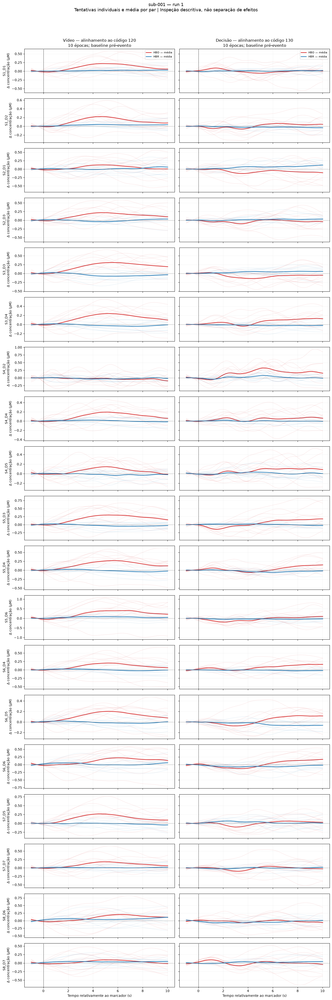

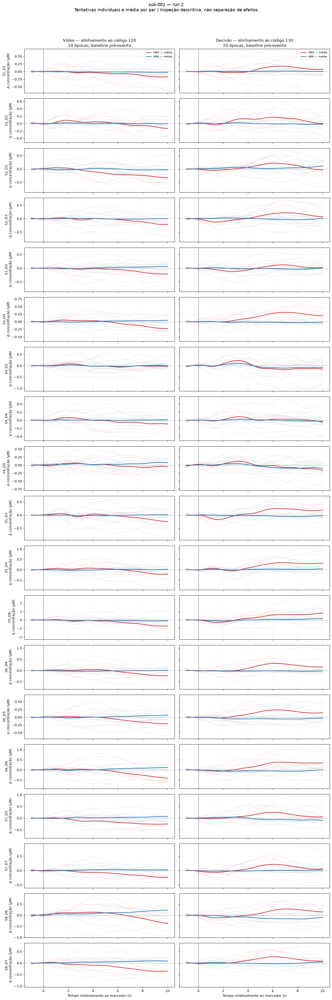

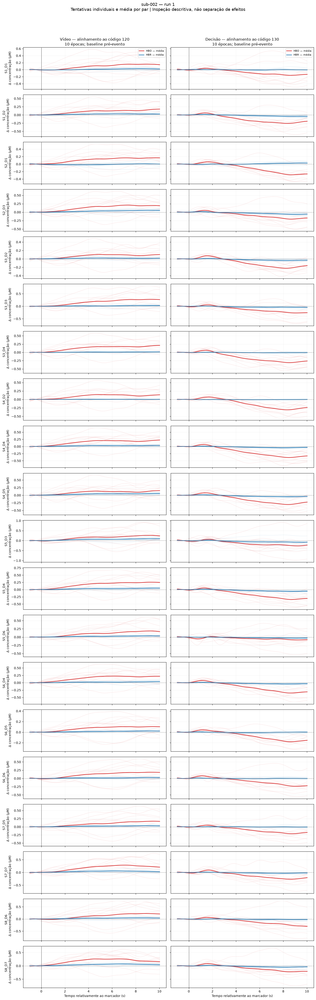

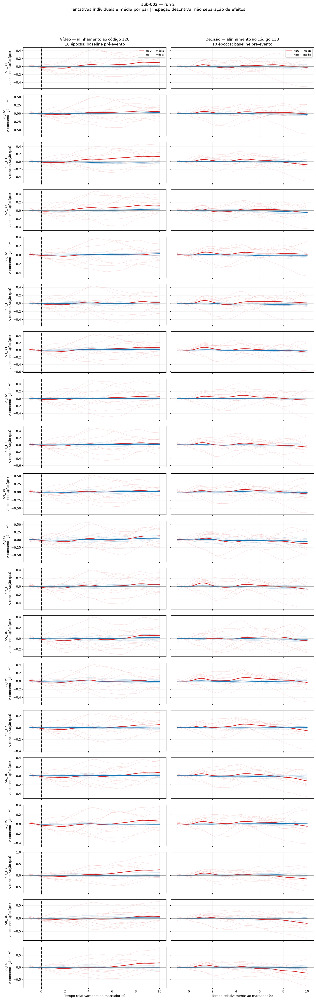


FIGURAS DE INSPEÇÃO CRIADAS
sujeito  run  n_pares  figura_guardada
sub-001    1       19             True
sub-001    2       19             True
sub-002    1       20             True
sub-002    2       20             True

Localização das figuras:

sub-001 — run 1
C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\fNIRS_epochs_derivatives\pilot_dm_epochs_v01\sub-001_ses-01_tk-dm_run-1_nirs_001\sub-001_ses-01_tk-dm_run-1_nirs_001_epochs_baseline_all_pairs.png

sub-001 — run 2
C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\fNIRS_epochs_derivatives\pilot_dm_epochs_v01\sub-001_ses-01_tk-dm_run-2_nirs_001\sub-001_ses-01_tk-dm_run-2_nirs_001_epochs_baseline_all_pairs.png

sub-002 — run 1
C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_A

In [11]:
# ============================================================
# ETAPA 13 — INSPEÇÃO VISUAL POR PAR E POR RUN
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if "piloto_epocas_com_baseline" not in globals():
    raise RuntimeError(
        "Executar primeiro a Etapa 12."
    )

FASES_INSPECAO = ("video", "decisao")

caminhos_figuras_inspecao = {}

for chave in sorted(piloto_runs):
    for fase in FASES_INSPECAO:
        if (chave, fase) not in piloto_epocas_com_baseline:
            raise RuntimeError(
                f"Faltam épocas para {chave}, {fase}."
            )

    id_gravacao = piloto_runs[chave]["id_gravacao"]

    pasta = Path(
        piloto_runs[chave]["pasta_saida_prevista"]
    )

    caminhos_figuras_inspecao[chave] = (
        pasta
        / f"{id_gravacao}_epochs_baseline_all_pairs.png"
    )

existentes = [
    str(caminho)
    for caminho in caminhos_figuras_inspecao.values()
    if caminho.exists()
]

if existentes:
    raise FileExistsError(
        "As seguintes figuras já existem. "
        "Não foram substituídas:\n"
        + "\n".join(existentes)
    )

registos_figuras = []

for chave in sorted(piloto_runs):
    sujeito, run = chave

    epocas_video = piloto_epocas_com_baseline[
        (chave, "video")
    ]

    epocas_decisao = piloto_epocas_com_baseline[
        (chave, "decisao")
    ]

    if epocas_video.ch_names != epocas_decisao.ch_names:
        raise RuntimeError(
            f"Os canais diferem entre fases: {chave}"
        )

    pares = list(dict.fromkeys(
        nome.split()[0]
        for nome in epocas_video.ch_names
    ))

    dados_por_fase = {}

    for fase in FASES_INSPECAO:
        epocas = piloto_epocas_com_baseline[(chave, fase)]

        if epocas.baseline is None:
            raise RuntimeError(
                f"Épocas sem baseline no objeto esperado: {chave}, {fase}"
            )

        dados = epocas.get_data() * 1e6

        if not np.isfinite(dados).all():
            raise RuntimeError(
                f"Valores não finitos: {chave}, {fase}"
            )

        dados_por_fase[fase] = dados

    fig, eixos = plt.subplots(
        nrows=len(pares),
        ncols=2,
        figsize=(14, 2.2 * len(pares)),
        sharex=True,
        sharey="row",
        squeeze=False,
    )

    for linha, par in enumerate(pares):
        for coluna, fase in enumerate(FASES_INSPECAO):
            ax = eixos[linha, coluna]

            epocas = piloto_epocas_com_baseline[
                (chave, fase)
            ]

            dados = dados_por_fase[fase]

            for cromoforo, cor in (
                ("hbo", "tab:red"),
                ("hbr", "tab:blue"),
            ):
                nome_canal = f"{par} {cromoforo}"

                if nome_canal not in epocas.ch_names:
                    raise RuntimeError(
                        f"Canal ausente: {nome_canal}, {chave}"
                    )

                indice = epocas.ch_names.index(nome_canal)
                curvas = dados[:, indice, :]

                ax.plot(
                    epocas.times,
                    curvas.T,
                    color=cor,
                    alpha=0.18,
                    linewidth=0.6,
                )

                ax.plot(
                    epocas.times,
                    curvas.mean(axis=0),
                    color=cor,
                    linewidth=1.8,
                    label=f"{cromoforo.upper()} — média",
                )

            ax.axvline(
                0,
                color="black",
                linestyle="--",
                linewidth=0.8,
            )

            ax.axhline(
                0,
                color="0.5",
                linewidth=0.5,
            )

            ax.grid(alpha=0.15)

            if coluna == 0:
                ax.set_ylabel(f"{par}\nΔ concentração (µM)")

            if linha == 0:
                titulo = (
                    "Vídeo — alinhamento ao código 120"
                    if fase == "video"
                    else "Decisão — alinhamento ao código 130"
                )

                ax.set_title(
                    f"{titulo}\n"
                    f"{len(epocas)} épocas; baseline pré-evento"
                )

                ax.legend(
                    loc="upper right",
                    fontsize=8,
                )

            if linha == len(pares) - 1:
                ax.set_xlabel(
                    "Tempo relativamente ao marcador (s)"
                )

    fig.suptitle(
        f"{sujeito} — run {run}\n"
        "Tentativas individuais e média por par | "
        "Inspeção descritiva, não separação de efeitos",
        fontsize=13,
        y=0.998,
    )

    fig.tight_layout(rect=(0, 0, 1, 0.98))

    caminho = caminhos_figuras_inspecao[chave]

    fig.savefig(
        caminho,
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    registos_figuras.append({
        "sujeito": sujeito,
        "run": run,
        "n_pares": len(pares),
        "figura_guardada": caminho.is_file(),
        "caminho": str(caminho),
    })

df_figuras_inspecao_piloto = pd.DataFrame(
    registos_figuras
)

print("\n" + "=" * 90)
print("FIGURAS DE INSPEÇÃO CRIADAS")
print("=" * 90)

print(
    df_figuras_inspecao_piloto[
        ["sujeito", "run", "n_pares", "figura_guardada"]
    ].to_string(index=False)
)

print("\nLocalização das figuras:")

for registo in registos_figuras:
    print(
        f"\n{registo['sujeito']} — run {registo['run']}\n"
        f"{registo['caminho']}"
    )

print("\nNão foram alterados sinais ou épocas.")
print("Não foram excluídas tentativas.")
print("Não foram combinadas runs.")
print("Não foram estimados contrastes ou efeitos de grupo.")
print("\nEtapa 13 concluída.")

## Ponto de paragem — 17/11/2026

### Versão
pilot_dm_epochs_v01

### Estado
Etapas executadas até à Etapa 13, inclusive.

Participantes do piloto:
- sub-001: runs 1 e 2.
- sub-002: runs 1 e 2.

### Processamento registado
- TDDR aplicado.
- Conversão HbO/HbR com PPF = 6.
- Filtro IIR Butterworth, order=4, SOS, fase zero,
  passa-banda de 0,01–0,50 Hz.
- SSR não aplicada nesta versão.
- Seleção de canais longos com distância >15 mm,
  excluindo os marcados como maus.
- 19 pares por run no sub-001.
- 20 pares por run no sub-002.
- Runs mantidas separadas.

### Eventos e épocas
- 40 tentativas reconstruídas: 10 por run.
- 120: início do vídeo.
- 130: início da decisão/resposta explícita.
- Intervalos reconstruídos entre marcadores;
  não usar os 10 s das anotações como duração real das fases.
- Épocas de inspeção pedidas de -1 a +10 s.
- Versões sem baseline e com baseline de -1 a 0 s guardadas.
- Dez épocas retidas por fase e run.
- Figuras por par e run guardadas.

### Interpretação
Inspeção visual preliminar realizada.
Diferenças entre runs e semelhanças entre canais
necessitam de investigação.
Não foram decididas novas exclusões.
Não considerar o sinal validado para inferência cortical.

### Pendências
- Guardar em ficheiro as tabelas temporais das Etapas 10–11,
  ou reconstruí-las a partir das anotações ao retomar.
- Confirmar o mapeamento dos eventos com a versão da tarefa
  efetivamente usada na recolha.
- Preparar e verificar a matriz do GLM.
- Verificar compatibilidade entre filtragem e modelo.
- Definir o controlo da fisiologia sistémica.
- Não combinar runs nem executar análise de grupo nesta fase.

### Retoma
Carregar os derivados já guardados desta versão.
Não executar indiscriminadamente todas as células:
algumas substituem ficheiros e outras param se já existirem saídas.
Não é necessário repetir o pré-processamento para recuperar a sessão.

GLM, betas e contrastes desta nova pipeline ainda não estimados.